# Right heart catheterization and 30-day mortality
Causal machine learning on the SUPPORT data, following the eight-step pipeline.

In 1996 Connors et al. reported that intensive care patients who received a right heart catheter on their first day were more likely to die within 30 days. Randomized trials later found no such effect. This notebook estimates the effect again, asks how much unmeasured confounding it would take to close the gap to the trials, and checks whether the effect differs between patients.

Throughout, $W$ is `swang1`, equal to 1 if the patient received a catheter on day 1, and $Y$ is `dth30`, equal to 1 if the patient died within 30 days. $X$ are the patient characteristics recorded on day 1. The ATE $\tau = E[Y(1) - Y(0)]$ is a risk difference and is reported in percentage points, $\tau(x)$ is the CATE.

| Step | Content |
|---|---|
| 1. Research question and data | load the data, handle missing covariates, unadjusted comparison |
| 2. Causal structure | confounder groups, admission period, DAG and backdoor check |
| 3. Estimand | target population, ATE, ATT, overlap population, CATE |
| 4. Assumptions | SUTVA, overlap, balance |
| 5. Estimation | nuisance models, causal forest, estimator ladder, comparison with published estimates |
| 6. Evaluation | calibration test, heterogeneity check, RATE |
| 7. Robustness | placebo, random common cause, semi-synthetic outcome, sensitivity benchmarked against the RCTs, specification |
| 8. Interpretation | best linear projection, partial dependence, profiles, summary, limitations |

Run the notebook with Restart Kernel and Run All. The first run downloads the data into `data/`. A full run takes about 10 to 20 minutes, most of it in the refits of Step 7.

## 0. Setup

In [43]:
import hashlib
import json
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
import networkx as nx
import statsmodels.api as sm
import statsmodels.formula.api as smf

from scipy import stats
from sklearn.metrics import brier_score_loss, roc_auc_score

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from econml.grf import CausalForest, RegressionForest

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 140)

SEED = 42
N_TREES = 2000               # econml needs a multiple of 4 for inference
N_TREES_REFUTE = 1000        # lighter forests for the refits in Step 7
LEAF_GRID = [5, 10, 20, 40]  # candidate min_samples_leaf values for the causal forest
N_FOLDS = 5
ALPHA = 0.05
Z_CRIT = stats.norm.ppf(1 - ALPHA / 2)

N_BOOT = 200                 # bootstrap draws for the standard error of the direct estimate in 5.4
N_BOOT_RATE = 500            # bootstrap draws for the RATE in 6.4
N_PLACEBO = 20               # placebo refits in 7.1, smallest possible p-value = 1 / 21
N_RCC = 10                    # refits with a random common cause in 7.2
N_SEMISYNTH = 20              # replicates per scenario in 7.3

# Published estimates, used for validation in Step 5 and as benchmark in Step 7
REF = {
    "connors_or": {"estimate": 1.24, "ci": (1.03, 1.49),
                   "source": "Connors et al. 1996, JAMA 276:889-897, propensity-matched OR for 30-day mortality"},
    "hirano_imbens_rd": {"range": (0.053, 0.062),
                         "source": "Hirano and Imbens 2001, Health Serv Outcomes Res Methodol 2:259-278, "
                                   "increase in 30-day mortality from weighting estimators"},
    "rct_meta_or": {"estimate": 1.04, "ci": (0.90, 1.20),
                    "source": "Shah et al. 2005, JAMA 294:1664-1670, meta-analysis of 13 RCTs with 5,051 patients"},
}

rng = np.random.default_rng(SEED)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
DATA_DIR = ROOT / "data"
RESULTS = {}                 # key numbers, exported at the end

# Plot style: no top and right spines, no grid, one accent color, source line under each figure
GREY, LIGHT, DARK = "#9A9A9A", "#D9D9D9", "#2B2B2B"
ACCENT, ACCENT_2, GOLD = "#0F6E56", "#C0502E", "#C9A227"
SOURCE = ("Source: SUPPORT study, RHC data from Vanderbilt Biostatistics, "
          "5,735 ICU patients, 1989 to 1994. Own analysis.")

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 11,
    "axes.titlesize": 14, "axes.labelsize": 11, "axes.labelcolor": DARK,
    "xtick.color": DARK, "ytick.color": DARK, "axes.edgecolor": GREY,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.major.size": 0, "ytick.major.size": 0,
})


def titles(ax, title, subtitle=None):
    ax.set_title(title, loc="left", fontweight="bold", color=DARK, pad=24 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=GREY, fontsize=10, va="bottom")


def save(fig, name, source=SOURCE):
    fig.text(0.01, -0.02, source, fontsize=8, color=GREY, ha="left", va="top")
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()


def fmt_ci(est, lo, hi, unit=" pp"):
    return f"{est:.1f}{unit}, 95% CI {lo:.1f} to {hi:.1f}"

---
## Step 1. Research question and data

### 1.1 Research question
The main question is by how many percentage points a catheter on day 1 changes 30-day mortality.

Two further questions follow from it. The randomized trials found no clear effect on mortality, so how strong would an unmeasured confounder have to be to move our estimate to theirs? Severity of illness that physicians saw at the bedside but that is not recorded in the data is the obvious candidate. And does the effect differ between patients, for example by disease category or severity?

The 1996 result had consequences. An editorial called for a moratorium on the catheter, and its use in the US was about two thirds lower in 2004 than in 1993. Whether the observational estimate shows real harm or residual confounding is therefore also a question about how far this kind of analysis can be trusted.

### 1.2 Data
The data come from SUPPORT, a study of seriously ill adults admitted to five US teaching hospitals between 1989 and 1994. Connors et al. analyzed 5,735 of these patients from nine disease categories, and Vanderbilt Biostatistics publishes this subset for methods research on causal inference. The study is observational. Physicians decided who got a catheter, so the two groups can differ in ways that also affect survival.

Almost all covariates refer to day 1, when the patient entered the study and the treatment decision was made. Two come from an interview on day 3 and are discussed in 1.3. Discharge, death and last-contact dates and the 180-day death indicator come later and are not used as covariates.


In [44]:
# [CONCEPT] Download the data once, verify the checksum, then always read the local copy
# [WHY]     The checksum guarantees that every run analyses exactly the same file
DATA_URL = "https://hbiostat.org/data/repo/rhc.csv"
DATA_SHA256 = "9ef4ab578be4b40ad5d97d3a7e08ffdc1f9f76aeeefee51b4996e4221556f8e8"


def load_rhc(path=DATA_DIR / "rhc.csv"):
    if not path.exists():
        path.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(DATA_URL, path)
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if digest != DATA_SHA256:
        raise ValueError(f"Checksum mismatch for {path}. Delete the file and run the cell again.")
    return pd.read_csv(path, index_col=0)


df_raw = load_rhc()

W_COL, Y_COL = "swang1", "dth30"
# [CONCEPT] Variables measured after the treatment decision are never used as covariates
# [WHY]     They can be affected by the catheter itself, and adjusting for them would bias the effect
POST_COLS = ["dschdte", "dthdte", "lstctdte", "death", "t3d30"]
ID_COLS = ["ptid", "sadmdte"]

# Short labels for tables and figures. Source: https://hbiostat.org/data/repo/rhc.html
LABELS = {
    "swang1": "Right heart catheterization", "dth30": "Death within 30 days",
    "t3d30": "Days survived up to day 30", "death": "Death within 180 days",
    "sadmdte": "Study admission date", "dschdte": "Discharge date", "dthdte": "Date of death",
    "lstctdte": "Date of last contact", "ptid": "Patient ID",
    "age": "Age", "sex": "Sex", "race": "Race", "edu": "Years of education", "income": "Income",
    "ninsclas": "Medical insurance", "cat1": "Primary disease category", "cat2": "Secondary disease category",
    "resp": "Respiratory diagnosis", "card": "Cardiovascular diagnosis", "neuro": "Neurological diagnosis",
    "gastr": "Gastrointestinal diagnosis", "renal": "Renal diagnosis", "meta": "Metabolic diagnosis",
    "hema": "Hematologic diagnosis", "seps": "Sepsis diagnosis", "trauma": "Trauma diagnosis",
    "ortho": "Orthopedic diagnosis",
    "adld3p": "Activities of daily living", "das2d3pc": "Duke Activity Status Index",
    "dnr1": "DNR order on day 1", "ca": "Cancer", "surv2md1": "SUPPORT 2-month survival estimate",
    "aps1": "APACHE score", "scoma1": "Glasgow Coma Score", "wtkilo1": "Weight", "temp1": "Temperature",
    "meanbp1": "Mean blood pressure", "resp1": "Respiratory rate", "hrt1": "Heart rate",
    "pafi1": "PaO2/FiO2 ratio", "paco21": "PaCO2", "ph1": "pH", "wblc1": "White blood cell count",
    "hema1": "Hematocrit", "sod1": "Sodium", "pot1": "Potassium", "crea1": "Creatinine",
    "bili1": "Bilirubin", "alb1": "Albumin", "urin1": "Urine output",
    "cardiohx": "Comorbidity: cardiovascular", "chfhx": "Comorbidity: congestive heart failure",
    "dementhx": "Comorbidity: dementia, stroke or Parkinson's", "psychhx": "Comorbidity: psychiatric",
    "chrpulhx": "Comorbidity: chronic pulmonary", "renalhx": "Comorbidity: chronic renal",
    "liverhx": "Comorbidity: cirrhosis or hepatic failure", "gibledhx": "Comorbidity: upper GI bleeding",
    "malighx": "Comorbidity: malignancy", "immunhx": "Comorbidity: immunosuppression",
    "transhx": "Transfer from another hospital", "amihx": "Comorbidity: definite myocardial infarction",
}

# dth30 and t3d30 are not in the documentation, so we check their meaning against the dates
days_to_death = df_raw["dthdte"] - df_raw["sadmdte"]
assert ((df_raw[Y_COL] == "Yes") == (days_to_death <= 30)).all()
assert (df_raw["t3d30"] == days_to_death.clip(upper=30).fillna(30)).all()


def role(col):
    if col == W_COL:
        return "treatment"
    if col == Y_COL:
        return "outcome"
    if col in POST_COLS:
        return "post-treatment, not used"
    if col in ID_COLS:
        return "identifier, not used"
    return "candidate confounder"


data_dictionary = pd.DataFrame({
    "label": [LABELS[c] for c in df_raw.columns],
    "role": [role(c) for c in df_raw.columns],
    "missing_share": df_raw.isna().mean().round(3).to_numpy(),
}, index=df_raw.columns)

n_raw, n_rhc = len(df_raw), int((df_raw[W_COL] == "RHC").sum())
n_conf = int((data_dictionary["role"] == "candidate confounder").sum())
print(f"{n_raw:,} patients, {n_rhc:,} with a catheter, {n_raw - n_rhc:,} without")
print(f"Missing outcomes: {df_raw[Y_COL].isna().sum()}, candidate confounders: {n_conf}")
RESULTS.update({"n_raw": n_raw, "n_rhc_raw": n_rhc})
data_dictionary.sort_values(["role", "missing_share"], ascending=[True, False])

5,735 patients, 2,184 with a catheter, 3,551 without
Missing outcomes: 0, candidate confounders: 53


,label,role,missing_share
cat2,Secondary disease category,candidate confounder,0.791
adld3p,Activities of daily living,candidate confounder,0.749
urin1,Urine output,candidate confounder,0.528
cat1,Primary disease category,candidate confounder,0.000
ca,Cancer,candidate confounder,0.000
cardiohx,Comorbidity: cardiovascular,candidate confounder,0.000
chfhx,Comorbidity: congestive heart failure,candidate confounder,0.000
dementhx,"Comorbidity: dementia, stroke or Parkinson's",candidate confounder,0.000
psychhx,Comorbidity: psychiatric,candidate confounder,0.000
chrpulhx,Comorbidity: chronic pulmonary,candidate confounder,0.000


In [45]:
# [CONCEPT] First look at the data: treatment, outcome and the key covariates
# [WHY]     The full table has 62 columns, so pandas hides most of them
PREVIEW_COLS = [W_COL, Y_COL, "cat1", "age", "sex", "aps1", "surv2md1", "meanbp1", "pafi1", "dnr1", "ca"]
mask = (df_raw[Y_COL] == "Yes") & (df_raw[W_COL] == "RHC") & (df_raw["age"] > 70) & (df_raw["sex"] == "Male")
df_raw.loc[mask, PREVIEW_COLS].rename(columns=LABELS).round(2).head(15)

,Right heart catheterization,Death within 30 days,Primary disease category,Age,Sex,APACHE score,SUPPORT 2-month survival estimate,Mean blood pressure,PaO2/FiO2 ratio,DNR order on day 1,Cancer
33,RHC,Yes,MOSF w/Malignancy,71.50,Male,105,0.12,33.0,285.00,No,Metastatic
89,RHC,Yes,ARF,93.02,Male,47,0.68,66.0,252.00,No,No
118,RHC,Yes,MOSF w/Sepsis,77.19,Male,81,0.39,48.0,122.44,No,No
146,RHC,Yes,MOSF w/Sepsis,70.13,Male,73,0.69,63.0,332.00,No,No
182,RHC,Yes,ARF,72.56,Male,72,0.22,60.0,90.00,No,Yes
183,RHC,Yes,ARF,78.72,Male,70,0.49,53.0,121.00,No,Yes
228,RHC,Yes,MOSF w/Sepsis,71.74,Male,76,0.44,42.0,240.81,No,No
247,RHC,Yes,Coma,78.36,Male,64,0.18,67.0,80.00,No,No
267,RHC,Yes,ARF,75.29,Male,54,0.34,147.0,176.00,No,Metastatic
277,RHC,Yes,ARF,79.90,Male,80,0.25,43.0,85.70,Yes,No


5,735 patients, 2,184 of them with a catheter. No outcome is missing, and 53 variables remain as candidate confounders. `missing_share` is the share of patients without a value for that variable.

### 1.3 Missing covariates
Three covariates have large gaps: the secondary disease category, activities of daily living and urine output. For each one the question is why the value is missing. If the gap itself carries information, it can be coded as a category. If it depends on what happened after day 1, neither the variable nor a missing indicator belongs in the adjustment set.

In [46]:
# [CONCEPT] Compare patients with and without a value on treatment rate and 30-day mortality
# [WHY]     If the gap goes along with the outcome, it may reflect the course after day 1
GAP_COLS = ["cat2", "adld3p", "urin1"]
treated = df_raw[W_COL] == "RHC"
died = df_raw[Y_COL] == "Yes"

rows = []
for col in GAP_COLS:
    miss = df_raw[col].isna()
    for value, group in [("missing", miss), ("observed", ~miss)]:
        rows.append({
            "variable": LABELS[col],
            "value": value,
            "patients": group.sum(),
            "% of all": 100 * group.mean(),
            "RHC": treated[group].sum(),
            "% RHC": 100 * treated[group].mean(),
            "died": died[group].sum(),
            "% died": 100 * died[group].mean(),
        })
    
gap_table = pd.DataFrame(rows).set_index(["variable", "value"]).round(1)

# Share with an ADL value by survival time, share with a urine output value by admission year.
# t3d30 is only used here to describe the gaps, never as a covariate.
survival_group = pd.cut(df_raw["t3d30"].where(died, 31), [0, 7, 14, 30, 31],
                        labels=["died on day 2 to 7", "died on day 8 to 14", "died on day 15 to 30", "alive at day 30"])
adl_by_survival = df_raw["adld3p"].notna().groupby(survival_group, observed=True).mean().rename_axis(None)
admission_year = pd.to_datetime(df_raw["sadmdte"], unit="D", origin="1960-01-01").dt.year   # SAS dates
urine_by_year = df_raw["urin1"].notna().groupby(admission_year).mean().rename_axis(None)

display(
    gap_table.style
    .format({"patients": "{:,}", "RHC": "{:,}", "died": "{:,}",
             "% of all": "{:.1f}%", "% RHC": "{:.1f}%", "% died": "{:.1f}%"})
    .bar(subset=["% RHC", "% died"], color="#9FD3C1", vmin=0, vmax=100)
)

print("% with an ADL value, by survival:")
print((100 * adl_by_survival).round(1).to_string(), "\n")
print("% with a urine output value, by admission year:")
print((100 * urine_by_year).round(1).to_string())


% with an ADL value, by survival:
died on day 2 to 7       3.3
died on day 8 to 14      5.7
died on day 15 to 30    11.5
alive at day 30         34.5 

% with a urine output value, by admission year:
1989     0.0
1990     0.0
1991     0.0
1992    85.8
1993    85.2
1994    86.7


The three gaps have different causes.

The secondary disease category only exists for patients who have a second condition from the list. A missing value means none. These patients receive a catheter less often, 36.9% against 42.7%, and die less often, 30.0% against 46.6%. We keep the variable and code the gap as its own category.

Activities of daily living is the opposite case. Among patients who died within the first week almost nobody has a value, among those alive at day 30 about a third do. Whether a value exists depends on how the patient fared after day 1, so the measurement was most likely taken later. We drop the variable and do not add a missing indicator either, because both would bring information from after the treatment decision into the adjustment set.

Urine output was not recorded before 1992 and is available for most patients after that, so most of the gap reflects when a patient was admitted. The rest of the gap is not random, though. Among the 459 patients from 1992 on without a value, 21.8% received a catheter, against 40.7% of the patients with a value. Filling in the variable for more than half of the patients is not credible, so we drop it. Kidney function is still covered by creatinine and the APACHE score. Whether the admission period itself is a confounder comes up again in Step 2.

In [47]:
# [CONCEPT] Questionnaire scores are whole numbers when measured, values filled in by a model usually are not
# [WHY]     The Duke Activity Status Index has no gaps, but it comes from the same day-3 interview as ADL.
#           If the filled-in values can be recognized, they reveal who missed the interview
dasi_whole = df_raw["das2d3pc"].round() == df_raw["das2d3pc"]
interview = df_raw["adld3p"].notna().map({True: "with day-3 interview", False: "without day-3 interview"})

print("% of DASI values that are whole numbers:")
print((dasi_whole.groupby(interview).mean() * 100).round(1).rename_axis(None).to_string(), "\n")
print("% died within 30 days:")
print((died.groupby(dasi_whole.map({True: "whole number", False: "not a whole number"})).mean() * 100)
      .round(1).rename_axis(None).to_string())

% of DASI values that are whole numbers:
with day-3 interview       71.5
without day-3 interview     0.2 

% died within 30 days:
not a whole number    39.0
whole number           8.5


A fourth gap is hidden. The Duke Activity Status Index describes how active the patient was before the illness and looks complete, but it comes from the same day-3 interview as activities of daily living. Among patients with an interview 72% of the values are whole numbers, among patients without one almost none are, so the study team filled in the missing values. Patients with a whole-number value die in 8.5% of cases, the others in 39.0%. A flexible model can tell the two apart and would learn who was well enough for the interview. We drop the index for the same reason as activities of daily living.

In [48]:
df = df_raw.copy()
df["cat2"] = df["cat2"].fillna("None")
DROP_COLS = ["adld3p", "urin1", "das2d3pc"] 
X_COLS = [c for c in df.columns if role(c) == "candidate confounder" and c not in DROP_COLS]

print(f"Covariates: {len(X_COLS)}, missing values left: {df[X_COLS].isna().sum().sum()}")
RESULTS.update({"n_covariates": len(X_COLS)})

Covariates: 50, missing values left: 0


### 1.4 Analysis sample
No outcome is missing, so all 5,735 patients stay in the analysis. Before fitting any model, the covariates are turned into numbers and the raw difference in 30-day mortality between the two groups is computed.

In [49]:
# [CONCEPT] Encode treatment, outcome and covariates as numbers
# [WHY]     All estimators need numeric input. Each category is compared with the most common or lowest level

# Text columns among the covariates
text_cols = df[X_COLS].select_dtypes(exclude="number").columns.tolist()

# Identify the Yes/No columns among the text columns, so they can be encoded as 1/0
YES_NO_COLS = [c for c in text_cols if set(df[c].unique()) == {"No", "Yes"}]

# Levels ordered by frequency, so the most common level becomes the reference category
CATEGORIES = {c: df[c].value_counts().index.tolist() for c in text_cols if c not in YES_NO_COLS + ["sex"]}

# Start from the 50 covariates. Work on a copy so that df itself stays unchanged.
X_df = df[X_COLS].copy()

# Yes/No columns become 1/0: "Yes" -> 1, "No" -> 0
X_df[YES_NO_COLS] = (X_df[YES_NO_COLS] == "Yes").astype(int)

# Sex becomes 1/0 as well: "Female" -> 1, "Male" -> 0
X_df["sex"] = (X_df["sex"] == "Female").astype(int)

# Columns with several levels, e.g. race = white / black / other.
# Fix the order of the levels so that the first one, the most common, becomes the reference.
for col, levels in CATEGORIES.items():
    X_df[col] = pd.Categorical(X_df[col], categories=levels)
    # A value missing from the list would silently turn into NaN, so stop if that happens
    assert X_df[col].notna().all(), f"unexpected category in {col}"

# One 0/1 column per level, without the reference level (drop_first=True).
# Example race: race_black and race_other. Both 0 means white.
X_df = pd.get_dummies(X_df, columns=list(CATEGORIES), drop_first=True, dtype=int)

# Convert the treatment and outcome to numeric arrays, and the covariates to a numeric matrix
W = (df[W_COL] == "RHC").to_numpy(dtype=float)
Y = (df[Y_COL] == "Yes").to_numpy(dtype=float)
X = X_df.to_numpy(dtype=float)
n = len(df)

# unadjusted comparison
# Compare 30-day mortality between patients with and without a catheter, without any adjustment.
# Y is 1 if the patient died, 0 if alive, so the mean of Y in a group is the share who died.
# Y[W == 1] keeps the outcome of the patients with a catheter, Y[W == 0] of those without.
naive = Y[W == 1].mean() - Y[W == 0].mean()          # 0.380 - 0.306 = 0.074, i.e. 7.4 points

# Standard error of the difference: how much it would vary by chance with other patients.
# More spread within a group (var) makes it larger, more patients (sum of W == 1) make it smaller.
se_naive = np.sqrt(Y[W == 1].var() / (W == 1).sum() + Y[W == 0].var() / (W == 0).sum())

# Summary table with one row per group.
# (W == 0).sum() counts patients without a catheter, Y[W == 0].sum() counts how many of them died.
mortality = pd.DataFrame({"patients": [int((W == 0).sum()), int((W == 1).sum())],
                          "died": [int(Y[W == 0].sum()), int(Y[W == 1].sum())],
                          "% died": [100 * Y[W == 0].mean(), 100 * Y[W == 1].mean()]},
                         index=["No RHC", "RHC"]).round(1)

# Output. X.shape[1] is the number of columns in X, 70 after the encoding above.
print(f"Analysis sample: {n:,} patients, {X.shape[1]} covariate columns after encoding")
print(mortality, "\n")

# 95% CI = estimate ± 1.96 × standard error (Z_CRIT = 1.96 from the setup).
# Multiplied by 100 to report percentage points instead of shares.
print("Unadjusted difference:", fmt_ci(100 * naive, 100 * (naive - Z_CRIT * se_naive), 100 * (naive + Z_CRIT * se_naive)))

# Store the key numbers in the results registry, exported at the end of the notebook
RESULTS.update({"n": n, "n_rhc": int(W.sum()), "n_no_rhc": int(n - W.sum()),
                "naive_rd": naive, "naive_rd_se": se_naive})

Analysis sample: 5,735 patients, 70 covariate columns after encoding
        patients  died  % died
No RHC      3551  1088    30.6
RHC         2184   830    38.0 

Unadjusted difference: 7.4 pp, 95% CI 4.8 to 9.9


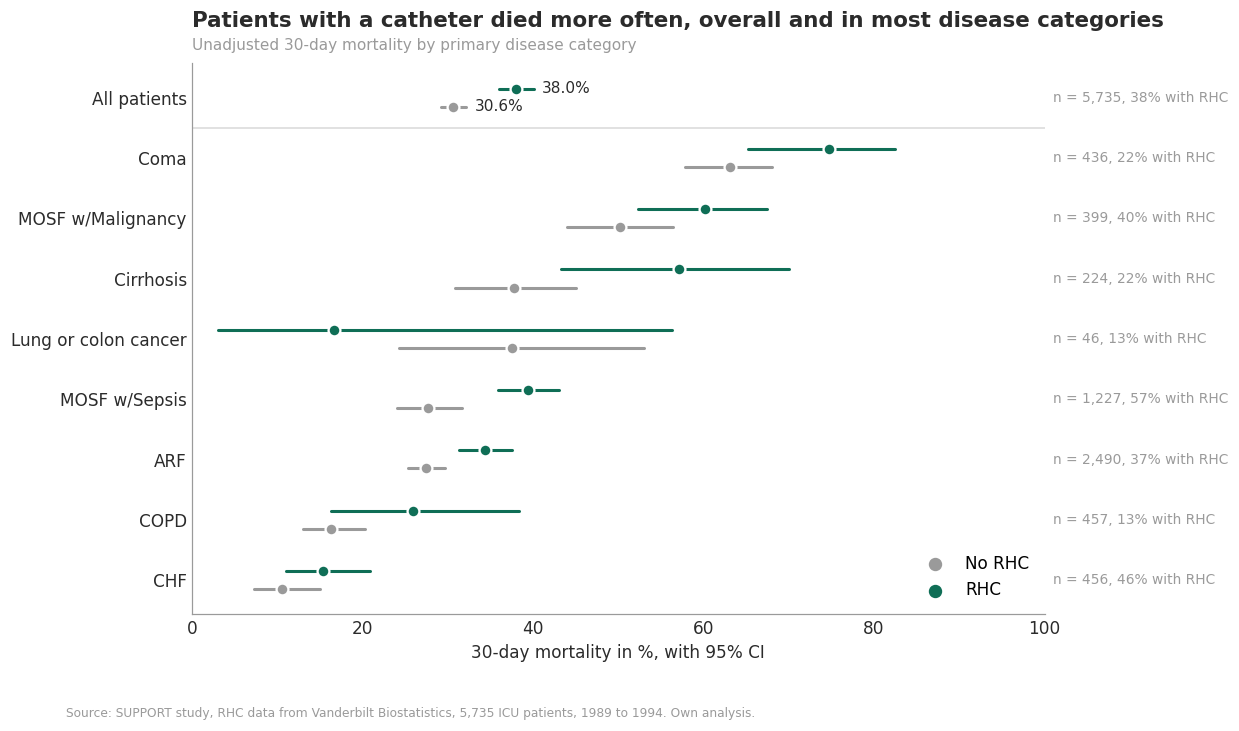

In [50]:
# [CONCEPT] Unadjusted 30-day mortality by treatment, overall and by disease category
# [WHY]     Shows the raw gap that the later steps have to explain, and where catheters were used

def pct_ci(y):
    """Share in % with a Wilson 95% CI, which stays between 0 and 100 also for small groups."""
    # p = share who died, m = number of patients in the group, z = 1.96 for a 95% interval
    p, m, z = y.mean(), len(y), Z_CRIT
    # The Wilson interval shifts its center slightly toward 50% and is therefore never below 0
    # or above 100. The simple formula p ± 1.96 × SE can fall below 0 in small groups.
    center = (p + z**2 / (2 * m)) / (1 + z**2 / m)
    half = z * np.sqrt(p * (1 - p) / m + z**2 / (4 * m**2)) / (1 + z**2 / m)
    # Returns three numbers in %: estimate, lower bound, upper bound
    return 100 * p, 100 * (center - half), 100 * (center + half)


# Lung cancer (39 patients) and colon cancer (7) are too small on their own, so they share one row.
# Only for this figure, the data keep both categories.
category = df["cat1"].replace({"Lung Cancer": "Lung or colon cancer", "Colon Cancer": "Lung or colon cancer"}).to_numpy()

# Sort the categories by overall mortality, highest first, so the figure reads from top to bottom
order = pd.Series(Y).groupby(category).mean().sort_values(ascending=False).index

# One True/False mask per row: "All patients" is True for everyone, each category only for its patients.
# The ** unpacks the category masks into the same dictionary after "All patients".
groups = {"All patients": np.ones(n, dtype=bool), **{c: category == c for c in order}}

fig, ax = plt.subplots(figsize=(10, 6.5))
for i, (name, mask) in enumerate(groups.items()):
    # Matplotlib counts rows from the bottom, so the first group gets the highest row number
    row = len(groups) - 1 - i

    # Two points per row: without catheter in gray slightly below, with catheter in teal slightly above
    for w, color, shift in [(0, GREY, -0.15), (1, ACCENT, 0.15)]:
        # mask & (W == w): patients of this group with (w = 1) or without (w = 0) a catheter
        est, lo, hi = pct_ci(Y[mask & (W == w)])
        ax.plot([lo, hi], [row + shift] * 2, color=color, lw=2, solid_capstyle="round")              # interval as line
        ax.scatter(est, row + shift, color=color, s=60, zorder=3, edgecolor="white", linewidth=1.5)  # estimate as dot
        # Write the value only in the top row, to keep the figure uncluttered
        if name == "All patients":
            ax.text(hi + 1, row + shift, f"{est:.1f}%", va="center", fontsize=10, color=DARK)

    # Right of the plot: group size and share with a catheter.
    # get_yaxis_transform: x in axis units (1.01 = just right of the plot), y in data units (the row)
    ax.text(1.01, row, f"n = {mask.sum():,}, {100 * W[mask].mean():.0f}% with RHC",
            transform=ax.get_yaxis_transform(), va="center", fontsize=9, color=GREY)

# Thin line that separates "All patients" from the categories
ax.axhline(len(groups) - 1.5, color=LIGHT, lw=1)

# Axes: group names on the y-axis, mortality from 0 to 100% on the x-axis
ax.set_yticks(range(len(groups))[::-1], labels=list(groups))
ax.set_xlim(0, 100)
ax.set_xlabel("30-day mortality in %, with 95% CI")

# Legend: two invisible dummy points that only carry the color and the label
ax.scatter([], [], color=GREY, s=60, label="No RHC")
ax.scatter([], [], color=ACCENT, s=60, label="RHC")
ax.legend(loc="lower right", frameon=False)

# Title, subtitle and source line (helper functions from the setup), then save to figures/
titles(ax, "Patients with a catheter died more often, overall and in most disease categories",
       "Unadjusted 30-day mortality by primary disease category")
save(fig, "fig01_mortality_by_group")

Patients with a catheter died more often, 38.0% against 30.6%. The raw difference is 7.4 percentage points, 95% CI 4.8 to 9.9. The gap also shows up within seven of the eight disease categories. Only in the small group with lung or colon cancer, 46 patients, does it go the other way, with a very wide interval.

Catheters were used very unevenly: in 57% of the patients with sepsis and multi-organ failure, but only in 13% of the COPD patients. Mortality also differs strongly between the categories, from about 10% in heart failure to over 60% in coma. The disease category is therefore a confounder, but adjusting for it alone does not remove the gap. Whether the other covariates explain it is the subject of Steps 2 to 5.

---
## Step 2. Causal structure

A covariate has to be adjusted for if it affects both the catheter decision and survival. The DAG in this step states which variables we believe play this role and which ones must stay out. The data cannot prove it, but writing it down makes the assumption explicit and open to criticism.

### 2.1 Confounders
We sort the 50 covariates into six groups. For each group there is a plausible path to the treatment and to the outcome.

| Group | Path to the catheter decision | Path to 30-day mortality |
|---|---|---|
| Diagnosis | heart failure and septic shock are classic reasons to measure pressures in the heart, COPD and coma are not | prognosis differs strongly between diseases, see Figure 1 |
| Severity scores | sicker patients were catheterized more often | the APACHE score and the SUPPORT estimate were built to predict death |
| Physiology and labs | low blood pressure and poor oxygenation call for close monitoring of the circulation | the same values signal failing organs |
| Comorbidities | heart disease makes a catheter more likely, cancer and dementia less likely | chronic disease lowers the chance to survive an acute illness |
| Demographics and insurance | age and insurance shape how aggressively a patient is treated | older patients die more often |
| Care context | a DNR order speaks against invasive procedures, transferred patients got a catheter more often | patients with a DNR order die twice as often |

To check that each group is really related to both, we predict the catheter and death from each group alone.

In [51]:
# [CONCEPT] Sort the 50 covariates into six groups by what they describe
# [WHY]     The DAG works with these groups. The assert makes sure no covariate is forgotten or listed twice.
#           sum(..., []) glues the lists together, e.g. sum([["a"], ["b", "c"]], []) gives ["a", "b", "c"]
CONFOUNDER_GROUPS = {
    "Diagnosis": ["cat1", "cat2", "resp", "card", "neuro", "gastr", "renal", "meta", "hema", "seps", "trauma", "ortho"],
    "Severity scores": ["aps1", "scoma1", "surv2md1"],
    "Physiology and labs": ["wtkilo1", "temp1", "meanbp1", "resp1", "hrt1", "pafi1", "paco21", "ph1",
                            "wblc1", "hema1", "sod1", "pot1", "crea1", "bili1", "alb1"],
    "Comorbidities": ["ca", "cardiohx", "chfhx", "dementhx", "psychhx", "chrpulhx", "renalhx",
                      "liverhx", "gibledhx", "malighx", "immunhx", "amihx"],
    "Demographics and insurance": ["age", "sex", "race", "edu", "income", "ninsclas"],
    "Care context": ["dnr1", "transhx"],
}
assert sorted(sum(CONFOUNDER_GROUPS.values(), [])) == sorted(X_COLS), "each covariate belongs to exactly one group"


def group_columns(cols):
    # After one-hot encoding a column name starts with the original name, e.g. "cat1_CHF" comes from "cat1"
    return [k for k in X_df.columns if k.split("_")[0] in cols]


def cv_auc(X_group, target):
    # [CONCEPT] Cross-validated AUC: every patient is predicted by a model that has not seen this patient
    # [WHY]     An in-sample AUC would reward overfitting, most of all for groups with many columns.
    #           AUC 0.5 means the group carries no information, 1.0 means it separates the classes perfectly
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    folds = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
    prob = cross_val_predict(model, X_group, target, cv=folds, method="predict_proba")[:, 1]
    return roc_auc_score(target, prob)


rows = []
for group, cols in CONFOUNDER_GROUPS.items():
    X_group = X_df[group_columns(cols)].to_numpy(dtype=float)
    rows.append({"group": group, "covariates": len(cols),
                 "AUC catheter": cv_auc(X_group, W), "AUC death": cv_auc(X_group, Y)})
rows.append({"group": "All covariates", "covariates": len(X_COLS),
             "AUC catheter": cv_auc(X, W), "AUC death": cv_auc(X, Y)})
group_table = pd.DataFrame(rows).set_index("group")
group_table.round(2)

,covariates,AUC catheter,AUC death
group,,,
Diagnosis,12,0.71,0.69
Severity scores,3,0.64,0.74
Physiology and labs,15,0.73,0.62
Comorbidities,12,0.59,0.60
Demographics and insurance,6,0.56,0.56
Care context,2,0.55,0.56
All covariates,50,0.79,0.76


Every group carries information about both the catheter and death, which is what makes it a confounder. Diagnosis and physiology predict the catheter best, with an AUC of 0.71 and 0.73. The severity scores predict death best, with 0.74. Comorbidities, demographics and care context are weaker on their own, between 0.55 and 0.60, but even a weak confounder can shift the estimate. All 50 covariates together reach 0.79 for the catheter and 0.76 for death, using a simple logistic regression.

So the catheter decision is far from random, and adjusting matters. It is also far from fully predictable, which leaves room for comparable patients in both groups. Step 4 looks at this overlap in detail.

### 2.2 Admission period
The admission date is not a patient characteristic, but practice and outcomes may have changed between 1989 and 1994.

In [52]:
# [CONCEPT] A variable is only a confounder if it is related to both W and Y
# [WHY]     If the catheter rate does not change with the admission year, the year cannot explain the gap,
#           even if mortality changes over time. admission_year comes from 1.3
by_year = pd.DataFrame({
    "patients": df.groupby(admission_year).size(),
    "% RHC": pd.Series(W, index=df.index).groupby(admission_year).mean() * 100,
    "% died": pd.Series(Y, index=df.index).groupby(admission_year).mean() * 100,
}).rename_axis("admission year")

# Mortality by year and treatment, one column for W = 0 and one for W = 1
rates = pd.DataFrame({"W": W, "Y": Y, "year": admission_year.to_numpy()}).pivot_table(index="year", columns="W", values="Y")
by_year["difference, pp"] = (rates[1.0] - rates[0.0]) * 100

# [CONCEPT] Average of the within-year differences, weighted by the number of patients per year
# [WHY]     If it is close to the raw difference, the year does not confound the comparison
within_year = np.average(by_year["difference, pp"], weights=by_year["patients"])

print(by_year.round(1).to_string(), "\n")
print(f"Raw difference: {naive * 100:.1f} pp, average difference within admission years: {within_year:.1f} pp")
RESULTS.update({"within_year_rd": within_year / 100})

# [CONCEPT] Questionnaire scores are whole numbers when measured, imputed values usually are not
# [WHY]     This shows whether the DASI values without a day-3 interview were filled in afterwards
dasi = df["das2d3pc"]
whole_number = dasi.round() == dasi
day3_interview = df_raw["adld3p"].notna().map({True: "with day-3 interview", False: "without day-3 interview"})
print("Share of DASI values that are whole numbers:")
print(whole_number.groupby(day3_interview).mean().round(3).rename_axis(None).to_string(), "\n")
print("Mean DASI:")
print(pd.Series({"RHC": dasi[W == 1].mean(), "No RHC": dasi[W == 0].mean(),
                 "died within 30 days": dasi[Y == 1].mean(), "alive at day 30": dasi[Y == 0].mean(),
                 "standard deviation, all patients": dasi.std()}).round(1).to_string())

RESULTS.update({"within_year_rd": within_year / 100})

                patients  % RHC  % died  difference, pp
admission year                                         
1989                 687   41.2    36.0             7.4
1990                1257   38.3    35.9             8.8
1991                 625   34.6    31.5             7.0
1992                1524   40.4    33.7             9.3
1993                1544   35.8    31.0             3.5
1994                  98   34.7    30.6            11.7 

Raw difference: 7.4 pp, average difference within admission years: 7.2 pp
Share of DASI values that are whole numbers:
with day-3 interview       0.715
without day-3 interview    0.002 

Mean DASI:
RHC                                 20.7
No RHC                              20.4
died within 30 days                 20.0
alive at day 30                     20.7
standard deviation, all patients     5.3


The catheter rate moves between 35% and 41% from year to year without a trend, while mortality falls a little over time. Within every admission year the catheter group dies more often, and the weighted average of these differences is 7.2 percentage points, close to the raw 7.4. The admission period is related to the outcome but hardly to the treatment, so it explains almost none of the gap. We leave it out.

### 2.3 DAG and backdoor check
The DAG summarizes the assumptions. The covariates X affect both the catheter W and death Y. Care after day 1, such as fluids, drugs and complications of the catheter itself, lies on the path from W to Y. It is part of the effect we want, so we do not adjust for it.

Two things are not in the data. Physicians saw more at the bedside than the recorded values show, and the five hospitals had different habits. Both can affect who gets a catheter and who survives. This unmeasured confounder U is the main threat to the analysis, and Step 7 asks how strong it would have to be to explain the gap to the randomized trials.

Day-1 values were recorded around the time of the decision. If some of them were taken after the catheter was placed, they could already reflect it. Like Connors et al., we treat them as baseline. The exclusion of patients who died or left within 48 hours affects who is in the sample, not what causes what, and is discussed in Step 3.

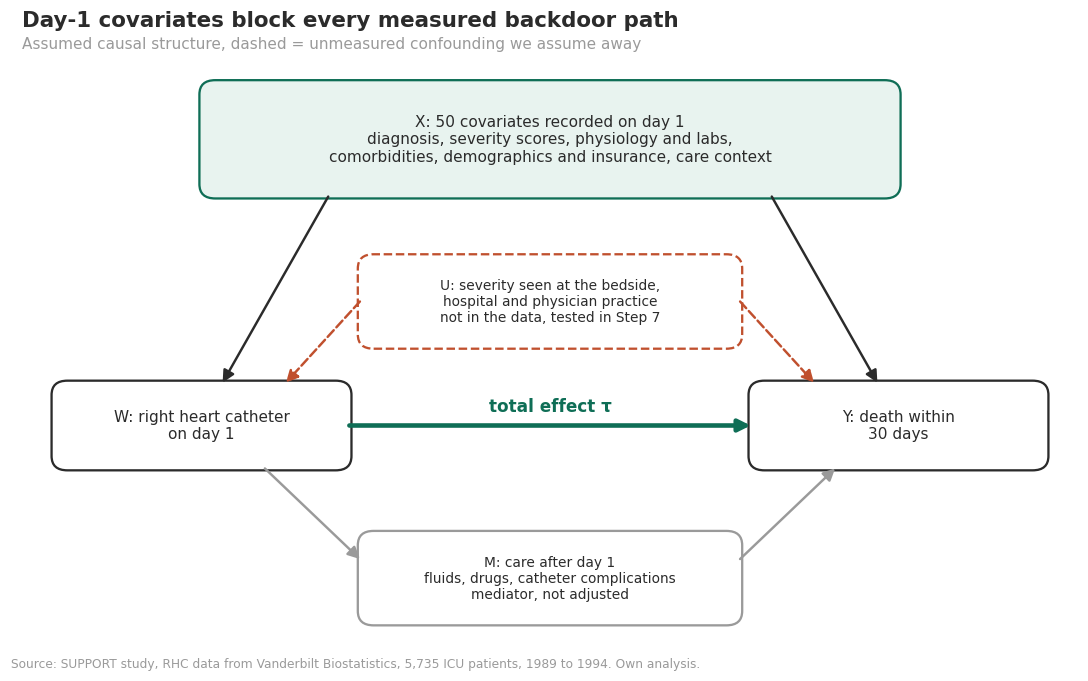

In [53]:
def draw_box(ax, x, y, w, h, text, face="white", edge=DARK, ls="-", fontsize=10):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.15",
                                facecolor=face, edgecolor=edge, linewidth=1.5, linestyle=ls))
    ax.text(x, y, text, ha="center", va="center", fontsize=fontsize, color=DARK)


def draw_arrow(ax, start, end, color=DARK, ls="-", lw=1.6):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=16, color=color,
                                 linewidth=lw, linestyle=ls, shrinkA=0, shrinkB=0))


# Boxes and arrows are placed by hand on a 10 x 6 canvas, the axes themselves are hidden
fig, ax = plt.subplots(figsize=(10, 6))
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.02)
ax.set_xlim(0, 10); ax.set_ylim(0.25, 6.2); ax.axis("off")
draw_box(ax, 5.0, 5.4, 6.6, 1.2, "X: 50 covariates recorded on day 1\ndiagnosis, severity scores, physiology and labs,\n"
         "comorbidities, demographics and insurance, care context", face="#E8F3EF", edge=ACCENT)
draw_box(ax, 1.7, 2.4, 2.8, 0.9, "W: right heart catheter\non day 1")
draw_box(ax, 8.3, 2.4, 2.8, 0.9, "Y: death within\n30 days")
draw_box(ax, 5.0, 3.7, 3.6, 0.95, "U: severity seen at the bedside,\nhospital and physician practice\nnot in the data, tested in Step 7",
         edge=ACCENT_2, ls="--", fontsize=9)
draw_box(ax, 5.0, 0.8, 3.6, 0.95, "M: care after day 1\nfluids, drugs, catheter complications\nmediator, not adjusted",
         edge=GREY, fontsize=9)

draw_arrow(ax, (2.9, 4.8), (1.9, 2.85))                               # X -> W
draw_arrow(ax, (7.1, 4.8), (8.1, 2.85))                               # X -> Y
draw_arrow(ax, (3.1, 2.4), (6.9, 2.4), color=ACCENT, lw=3)            # W -> Y: the effect we want
ax.text(5.0, 2.55, "total effect τ", color=ACCENT, ha="center", fontweight="bold")
draw_arrow(ax, (2.3, 1.95), (3.2, 1.0), color=GREY)                   # W -> M
draw_arrow(ax, (6.8, 1.0), (7.7, 1.95), color=GREY)                   # M -> Y
draw_arrow(ax, (3.2, 3.7), (2.5, 2.85), color=ACCENT_2, ls="--")      # U -> W
draw_arrow(ax, (6.8, 3.7), (7.5, 2.85), color=ACCENT_2, ls="--")      # U -> Y
titles(ax, "Day-1 covariates block every measured backdoor path",
       "Assumed causal structure, dashed = unmeasured confounding we assume away")
save(fig, "fig02_dag")

In [54]:
# [CONCEPT] Backdoor criterion: adjusting for a set Z gives the causal effect of W on Y if
#           1. no variable in Z is caused by W, and
#           2. Z blocks every backdoor path, a path that starts with an arrow INTO W.
#           Example of a backdoor path: W <- aps1 -> Y. Sicker patients get a catheter more often
#           and also die more often, which creates a link between W and Y that the catheter did not cause.
# [WHY]     The formal version of "adjusting for X is enough". The check runs on the DAG we drew, not on
#           the data, so it can only tell us whether our assumptions are consistent and what would break them.
#           We test three cases: the assumed DAG, the same DAG with an unmeasured confounder U,
#           and the mistake of also adjusting for the mediator M

# networkx renamed the function in version 3.3, this line works with old and new versions
d_separated = getattr(nx, "is_d_separator", None) or getattr(nx, "d_separated")


def satisfies_backdoor(G, w, y, Z):
    Z = set(Z)

    # Condition 1: never adjust for something W causes.
    # nx.descendants returns every node reachable from W along the arrows, here {"M", "Y"}.
    # & is the intersection of two sets, e.g. {"age", "M"} & {"M", "Y"} gives {"M"}, which counts as True
    if Z & nx.descendants(G, w):
        return False

    # Remove all arrows that leave W, here W -> Y and W -> M.
    # What still connects W and Y afterwards can only be a backdoor path
    G_back = G.copy()
    G_back.remove_edges_from(list(G.out_edges(w)))

    # Condition 2: W and Y are d-separated given Z if every remaining path is blocked.
    # A path like W <- aps1 -> Y is blocked as soon as aps1 is in Z, i.e. we compare patients with the same score
    return d_separated(G_back, {w}, {y}, Z)


# The assumed DAG: every covariate points to W and to Y, which gives 50 backdoor paths W <- x -> Y.
# The catheter acts on death directly and through the care after day 1, M
G = nx.DiGraph()
G.add_edges_from([(x, "W") for x in X_COLS] + [(x, "Y") for x in X_COLS])
G.add_edges_from([("W", "Y"), ("W", "M"), ("M", "Y")])

# Same DAG plus U, e.g. severity seen at the bedside. U is not in the data, so it can never be in Z
G_with_U = G.copy()
G_with_U.add_edges_from([("U", "W"), ("U", "Y")])

# Expected: True, all 50 backdoor paths are blocked by X
bd_assumed = satisfies_backdoor(G, "W", "Y", X_COLS)
print(f"X satisfies the backdoor criterion in the assumed DAG:       {bd_assumed}")
# Expected: False, the path W <- U -> Y stays open
print(f"X satisfies it if an unmeasured confounder U exists:          {satisfies_backdoor(G_with_U, 'W', 'Y', X_COLS)}")
# Expected: False, M is caused by W and breaks condition 1
print(f"X plus the mediator M satisfies it:                           {satisfies_backdoor(G, 'W', 'Y', X_COLS + ['M'])}")
RESULTS["backdoor_assumed_dag"] = bd_assumed

X satisfies the backdoor criterion in the assumed DAG:       True
X satisfies it if an unmeasured confounder U exists:          False
X plus the mediator M satisfies it:                           False


True, False, False. The 50 covariates are enough only if the DAG is right. An unmeasured confounder like the severity seen at the bedside breaks the identification, and so does adjusting for anything that happens after the catheter is placed. Since U cannot be ruled out, Step 7 measures how strong it would have to be.

---
## Step 3. Estimand

Before fitting any model, we fix which effect we want, for whom and on which scale. The answer to "does the catheter harm patients?" depends on all three.

### 3.1 Target population
The sample is not all intensive care patients. SUPPORT excluded patients who died or were discharged within 48 hours of study entry, while the catheter decision falls into the first day. The dates show this directly.

In [55]:
# [CONCEPT] SUPPORT excluded patients who died or were discharged within 48 hours of study entry
# [WHY]     The catheter decision falls into the first day, so the sample is selected on what happened after it.
#           The dates only describe this here and are never used as covariates.
#           days_to_death comes from 1.2, e.g. 2 means the patient died two days after study entry
days_to_discharge = df["dschdte"] - df["sadmdte"] # dschdte = discharge date, sadmdte = study admission date

first_days = pd.DataFrame({
    "earliest day": [days_to_death.min(), days_to_discharge.min()],
    "patients on that day": [(days_to_death == days_to_death.min()).sum(),
                             (days_to_discharge == days_to_discharge.min()).sum()],
}, index=["death", "discharge"]).astype(int)

# How many of the 30-day deaths happen in the first week? If many, the excluded first two days matter too
early_deaths = (days_to_death <= 7).sum()
print(first_days, "\n")
print(f"Deaths in the first week: {early_deaths:,}, {early_deaths / Y.sum() * 100:.0f}% of all deaths within 30 days")

           earliest day  patients on that day
death                 2                   126
discharge             2                   163 

Deaths in the first week: 874, 46% of all deaths within 30 days


No patient died or left the hospital before day 2, while 126 died and 163 were discharged on exactly that day. Early deaths are common: 874 patients, 46% of all deaths within 30 days, died in the first week. The missing first two days are therefore unlikely to be a small group.

This matters because the selection happens after the treatment decision. If the catheter caused deaths in the first two days, those patients are missing from the catheter group, and the catheter looks safer than it is. If it prevented early deaths, the catheter group keeps very sick patients whose counterparts without a catheter died early and dropped out, and the catheter looks more harmful than it is. The data cannot tell which way it goes.

Our target population is therefore patients who were still alive and in hospital two days after study entry, the same population Connors et al. analyzed. The trials counted deaths from randomization on, which is one reason why the two kinds of evidence need not agree. Step 8 comes back to this in the limitations.

### 3.2 Estimands
All estimands compare the same patients under both treatments, $Y(1)$ with and $Y(0)$ without a catheter. They differ only in whom they average over.

- **ATE** $\tau = E[Y(1) - Y(0)]$ is the primary estimand: the change in 30-day mortality if every patient in the population got a catheter compared with nobody. It summarizes the effect over all patients in the study, and Hirano and Imbens report the same quantity. A moratorium asks what would change if the patients who now get a catheter did without one, which is closer to the ATT.
- **ATT** $\tau_T = E[Y(1) - Y(0) \mid W = 1]$ averages only over patients who actually got a catheter. Connors et al. matched catheter patients to similar patients without one, which comes closest to this estimand.
- **ATO** $\tau_O = E[h(X)\,\tau(X)] \,/\, E[h(X)]$ with $h(x) = e(x)\,(1 - e(x))$ averages over patients for whom both decisions were realistic. $e(x)$ is the probability of getting a catheter given the covariates. A patient with $e(x) = 0.5$ gets the largest weight, 0.25, a patient with $e(x) = 0.95$ only 0.05. Trials can only enroll patients for whom physicians accept either treatment, so the ATO is the closest match to the randomized evidence. It also stays reliable if Step 4 finds patients who almost always or almost never get a catheter.
- **CATE** $\tau(x) = E[Y(1) - Y(0) \mid X = x]$ is the average effect for patients like $x$, not the effect for one particular person. Steps 6 and 8 use it to look for groups that might benefit or be harmed.

All effects are risk differences in percentage points, the number of extra or avoided deaths per 100 patients. Connors et al. and the trials report odds ratios instead. An odds ratio changes with the set of covariates even when there is no confounding at all, which makes it hard to compare across studies. We therefore keep risk differences and convert the published odds ratios in Step 5.

The effect is a total effect. It includes everything the catheter sets in motion after day 1, the mediator M from Step 2.

In [56]:
# [CONCEPT] Write the estimand down once, so every later step refers to the same definition
# [WHY]     The table ends up in RESULTS and in the export at the end, next to the numbers it describes
ESTIMAND = {
    "primary": "ATE = E[Y(1) - Y(0)]",
    "comparison with Connors et al.": "ATT = E[Y(1) - Y(0) | W = 1]",
    "comparison with the trials": "ATO, overlap-weighted average effect",
    "heterogeneity": "CATE tau(x) = E[Y(1) - Y(0) | X = x]",
    "scale": "risk difference in percentage points",
    "outcome": "death within 30 days of study entry",
    "effect type": "total effect, mediators not adjusted",
    "population": "alive and in hospital two days after study entry",
}
RESULTS.update({f"estimand_{k}": v for k, v in ESTIMAND.items()})
pd.Series(ESTIMAND, name="estimand").to_frame()

,estimand
primary,ATE = E[Y(1) - Y(0)]
comparison with Connors et al.,ATT = E[Y(1) - Y(0) | W = 1]
comparison with the trials,"ATO, overlap-weighted average effect"
heterogeneity,CATE tau(x) = E[Y(1) - Y(0) | X = x]
scale,risk difference in percentage points
outcome,death within 30 days of study entry
effect type,"total effect, mediators not adjusted"
population,alive and in hospital two days after study entry


---
## Step 4. Assumptions

Three assumptions turn the estimands from Step 3 into something the data can answer.

**SUTVA** cannot be tested, only argued.
- No hidden versions of the treatment: "a catheter on day 1" covers different physicians, insertion techniques and, above all, different ways of acting on the measurements. $Y(1)$ is the outcome under the catheter as it was used in these five hospitals between 1989 and 1994, not under catheter use in general.
- No interference: one patient's catheter does not change another patient's survival. This is plausible, although a busy unit might give less attention to other patients while catheters are placed.

**Overlap** can be checked: every kind of patient needs a real chance of both decisions.

**Unconfoundedness** cannot be tested. The 50 covariates must block every backdoor path, as argued in Step 2. The data can only show whether the measured covariates are balanced after weighting. Unmeasured confounding is the topic of Step 7.

### 4.1 Overlap

Propensity range: 0.002 to 0.990
Outside 0.1 to 0.9: 17.7% of all patients, 6.0% with a catheter, 24.9% without
  below 0.1: 920 patients, above 0.9: 94 patients


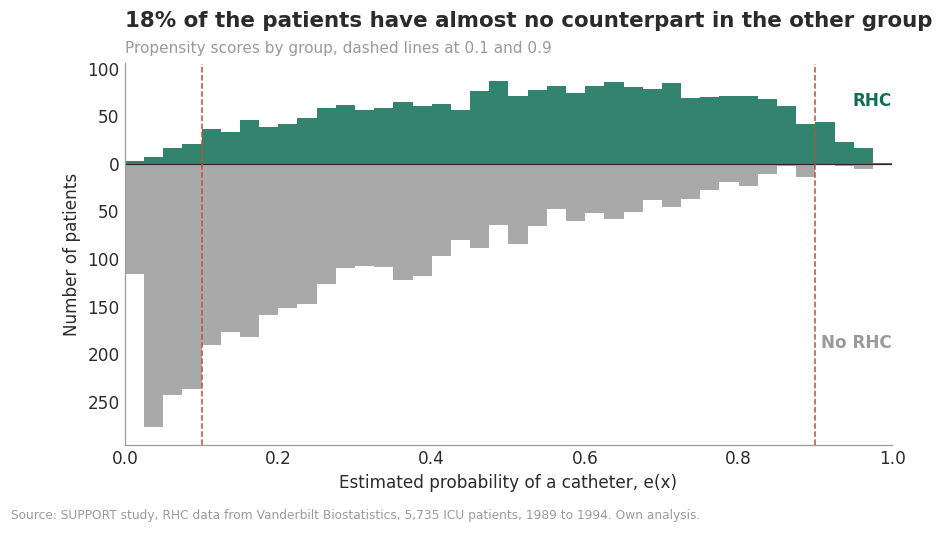

In [57]:
# [CONCEPT] Propensity score e(x) = P(W = 1 | X = x), the probability of getting a catheter given the covariates
# [WHY]     Overlap means that every kind of patient had a real chance of both decisions. If e(x) is close
#           to 0 or 1, there is nobody comparable in the other group, and the ATE has to be extrapolated.
#           A logistic regression on all 70 columns, cross-fitted as in 2.1: each patient's score comes
#           from a model that has not seen this patient
ps_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
folds = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
e_lr = cross_val_predict(ps_model, X, W, cv=folds, method="predict_proba")[:, 1]

# Rule of thumb by Crump et al. 2009: estimates get unstable for patients outside 0.1 to 0.9
PS_LOW, PS_HIGH = 0.1, 0.9
outside = (e_lr < PS_LOW) | (e_lr > PS_HIGH)
print(f"Propensity range: {e_lr.min():.3f} to {e_lr.max():.3f}")
print(f"Outside {PS_LOW} to {PS_HIGH}: {outside.mean():.1%} of all patients, "
      f"{outside[W == 1].mean():.1%} with a catheter, {outside[W == 0].mean():.1%} without")
print(f"  below {PS_LOW}: {(e_lr < PS_LOW).sum():,} patients, above {PS_HIGH}: {(e_lr > PS_HIGH).sum():,} patients")
RESULTS.update({"ps_min": e_lr.min(), "ps_max": e_lr.max(), "ps_share_outside": outside.mean()})

# Mirrored histogram: catheter patients above the axis, the others below
fig, ax = plt.subplots(figsize=(9, 4.5))
bins_ps = np.linspace(0, 1, 41)
h1, _ = np.histogram(e_lr[W == 1], bins=bins_ps)
h0, _ = np.histogram(e_lr[W == 0], bins=bins_ps)
ax.bar(bins_ps[:-1], h1, width=np.diff(bins_ps), align="edge", color=ACCENT, alpha=0.85)
ax.bar(bins_ps[:-1], -h0, width=np.diff(bins_ps), align="edge", color=GREY, alpha=0.85)
ax.axhline(0, color=DARK, lw=0.8)
for xv in (PS_LOW, PS_HIGH):
    ax.axvline(xv, color=ACCENT_2, ls="--", lw=1)
ax.text(1, h1.max() * 0.7, "RHC", color=ACCENT, ha="right", fontweight="bold")
ax.text(1, -h0.max() * 0.7, "No RHC", color=GREY, ha="right", fontweight="bold")
ax.set_xlim(0, 1)
ax.set_xlabel("Estimated probability of a catheter, e(x)")
ax.set_ylabel("Number of patients")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{abs(int(v))}"))   # no minus signs below the axis
titles(ax, f"{outside.mean():.0%} of the patients have almost no counterpart in the other group",
       "Propensity scores by group, dashed lines at 0.1 and 0.9")
save(fig, "fig04a_overlap")

The propensity scores range from 0.002 to 0.990. 18% of the patients lie outside 0.1 to 0.9, most of them below 0.1: 920 patients, nearly all of them without a catheter, look so unlike the catheter patients that the model gives them almost no chance of getting one. Only 6% of the catheter patients lie outside the bounds, against 25% of the others.

This is the problem announced in Step 3. For the ATE, the effect for these patients has to be extrapolated from patients who are not like them. We keep the ATE as primary estimand but always report the ATO next to it, which gives these patients little weight. If the two differ much, the ATE rests on extrapolation.

### 4.2 Balance

Stabilized weights: mean 1.06, should be close to 1, range 0.38 to 93.7
Effective sample size with IP weights:      355 of 2,184 with a catheter, 1,683 of 3,551 without
Effective sample size with overlap weights: 1,752 with a catheter, 2,261 without

                                         unadjusted  IP weighted  overlap weighted
APACHE score                                  0.355        0.008             0.001
Mean blood pressure                           0.322        0.070             0.003
PaO2/FiO2 ratio                               0.306        0.011             0.002
Primary disease category: MOSF w/Sepsis       0.293        0.008             0.001
Neurological diagnosis                        0.250        0.040             0.002
Primary disease category: COPD                0.242        0.053             0.002
Cardiovascular diagnosis                      0.209        0.042             0.002
Creatinine                                    0.191        0.071             0.001

C

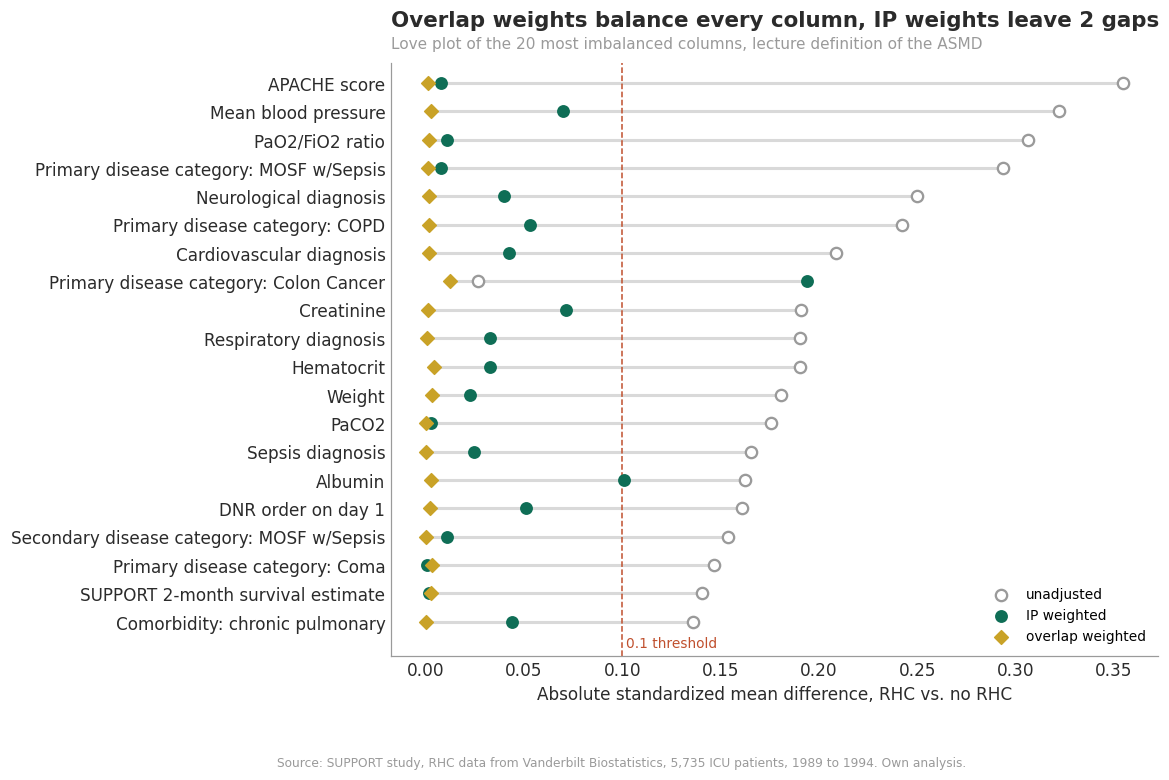

In [58]:
# [CONCEPT] Stabilized inverse probability weights: SW_i = P(W = w_i) / P(W = w_i | X_i)
# [WHY]     Weighting creates a pseudo-population in which X no longer predicts W. If the weights work,
#           the covariates are balanced between the groups, and the love plot checks exactly this.
#           Example: a catheter patient with e = 0.2 is rare among catheter patients and counts as 0.38 / 0.2 = 1.9
p_rhc = W.mean()
sw = np.where(W == 1, p_rhc / e_lr, (1 - p_rhc) / (1 - e_lr))

# [CONCEPT] Overlap weights, the weights behind the ATO from Step 3: 1 - e for catheter patients, e for the others
# [WHY]     No weight can exceed 1, so they never explode. Patients near e = 0 or 1 simply count less
ow = np.where(W == 1, 1 - e_lr, e_lr)


def ess(weights):
    # Kish's effective sample size: how many unweighted patients a weighted group is worth.
    # Example: 100 patients with weight 1 give 100, one of them with weight 50 instead drops it to about 9
    return weights.sum() ** 2 / (weights ** 2).sum()


print(f"Stabilized weights: mean {sw.mean():.2f}, should be close to 1, range {sw.min():.2f} to {sw.max():.1f}")
print(f"Effective sample size with IP weights:      {ess(sw[W == 1]):,.0f} of {(W == 1).sum():,} with a catheter, "
      f"{ess(sw[W == 0]):,.0f} of {(W == 0).sum():,} without")
print(f"Effective sample size with overlap weights: {ess(ow[W == 1]):,.0f} with a catheter, "
      f"{ess(ow[W == 0]):,.0f} without\n")


def asmd(z, w, weights):
    # Absolute standardized mean difference, lecture definition: |mean1 - mean0| / sqrt(s1^2 + s0^2).
    # Many packages divide by sqrt((s1^2 + s0^2) / 2) instead, which gives values larger by sqrt(2)
    stats_ = []
    for g in (1, 0):
        m = w == g
        mu = np.average(z[m], weights=weights[m])
        stats_.append((mu, np.average((z[m] - mu) ** 2, weights=weights[m])))
    (mu1, v1), (mu0, v0) = stats_
    return abs(mu1 - mu0) / np.sqrt(v1 + v0)


def col_label(col):
    # "cat1_CHF" becomes "Primary disease category: CHF", plain columns keep their label
    base, _, level = col.partition("_")
    return f"{LABELS[base]}: {level}" if level else LABELS[base]


# One row per encoded column, the same 70 columns the models see
balance = pd.DataFrame({
    "unadjusted": [asmd(X_df[c].to_numpy(dtype=float), W, np.ones(n)) for c in X_df.columns],
    "IP weighted": [asmd(X_df[c].to_numpy(dtype=float), W, sw) for c in X_df.columns],
    "overlap weighted": [asmd(X_df[c].to_numpy(dtype=float), W, ow) for c in X_df.columns],
}, index=[col_label(c) for c in X_df.columns])
print(balance.sort_values("unadjusted", ascending=False).round(3).head(8).to_string())
print("\nColumns above 0.1:", (balance > 0.1).sum().to_dict())
print("Above 0.1 after IP weighting:", ", ".join(balance.index[balance["IP weighted"] > 0.1]))
RESULTS.update({"asmd_max_unadjusted": balance["unadjusted"].max(), "asmd_max_ipw": balance["IP weighted"].max(),
                "asmd_max_overlap": balance["overlap weighted"].max()})

# Love plot of the 20 columns with the largest imbalance before or after IP weighting
shown = balance.loc[balance[["unadjusted", "IP weighted"]].max(axis=1).sort_values().index[-20:]]
fig, ax = plt.subplots(figsize=(9, 7))
yy = np.arange(len(shown))
ax.hlines(yy, shown.min(axis=1), shown.max(axis=1), color=LIGHT, lw=2, zorder=1)
ax.scatter(shown["unadjusted"], yy, facecolors="white", edgecolors=GREY, s=55, lw=1.5, zorder=2, label="unadjusted")
ax.scatter(shown["IP weighted"], yy, color=ACCENT, s=55, zorder=3, label="IP weighted")
ax.scatter(shown["overlap weighted"], yy, color=GOLD, marker="D", s=40, zorder=4, label="overlap weighted")
ax.axvline(0.1, color=ACCENT_2, ls="--", lw=1)
ax.text(0.102, -0.9, "0.1 threshold", color=ACCENT_2, fontsize=9)
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.set_yticks(yy, labels=shown.index)
ax.set_ylim(-1.2, len(shown) - 0.3)
ax.set_xlabel("Absolute standardized mean difference, RHC vs. no RHC")
n_gaps = int((balance["IP weighted"] > 0.1).sum())
titles(ax, f"Overlap weights balance every column, IP weights leave {n_gaps} gaps",
       "Love plot of the 20 most imbalanced columns, lecture definition of the ASMD")
save(fig, "fig04b_love_plot")

Before weighting, 26 of the 70 columns differ by more than 0.1. The largest gaps are the APACHE score, blood pressure, oxygenation and sepsis with multi-organ failure: the catheter patients were sicker.

Inverse probability weighting removes almost all of these gaps, but at a price. The largest weight is 94, for a patient with colon cancer who got a catheter although the model gave this a probability of 0.4%. This one patient counts as much as 94 average patients and opens a new gap for colon cancer. The effective sample size of the catheter group drops from 2,184 to 355. Overlap weights balance all 70 columns almost exactly and keep effective sample sizes of 1,752 and 2,261.

Balance after weighting only covers what was measured. Whether physicians saw something the data do not show, the severity at the bedside from Step 2, cannot be checked here.

---
## Step 5. Estimation

Two parts. First the grf workflow: nuisance models, a causal forest on the residuals and its doubly robust estimates of the three estimands from Step 3. Then the estimator ladder from the raw difference to AIPW, and a comparison with the published estimates.

### 5.1 Nuisance models
Two regression forests with out-of-bag predictions, as in grf. For comparison we fit logistic regressions with 5-fold cross-fitting. Double machine learning allows any learner, but the better the nuisance models, the closer the estimate gets to the truth.

In [59]:
# [CONCEPT] Two nuisance functions, as in the grf workflow:
#           m(x) = E[Y | X = x], the expected mortality of a patient like x, whatever the treatment
#           e(x) = P(W = 1 | X = x), the propensity score
# [WHY]     The causal forest works with the residuals Y - m(x) and W - e(x). The predictions are out-of-bag:
#           the prediction for patient i only uses trees grown without patient i, which is cross-fitting for free.
#           honest=False: honesty matters for the inference of the causal forest, not here. An honest forest
#           pulled e(x) toward the middle, from 0.08 to 0.73, and was clearly worse calibrated
def fit_m_hat(X_, Y_, n_trees=N_TREES, seed=SEED):
    rf = RegressionForest(n_estimators=n_trees, min_samples_leaf=5, honest=False, random_state=seed).fit(X_, Y_)
    return rf.oob_predict(X_).ravel()


def fit_e_hat(X_, W_, n_trees=N_TREES, seed=SEED, clip=0.01):
    rf = RegressionForest(n_estimators=n_trees, min_samples_leaf=5, honest=False, random_state=seed).fit(X_, W_)
    # Clip away from 0 and 1, because the doubly robust score divides by e(1 - e)
    return np.clip(rf.oob_predict(X_).ravel(), clip, 1 - clip)


m_hat = fit_m_hat(X, Y)
e_hat = fit_e_hat(X, W)

# Logistic benchmark with the same folds as in Step 4: fitted on four folds, predicted on the fifth.
# mu1 and mu0 are fitted separately within each treatment group, mu_w(x) = E[Y | W = w, X = x].
# They are needed for the classic AIPW in 5.4
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
m_par, mu1_par, mu0_par = np.zeros(n), np.zeros(n), np.zeros(n)
for tr, te in folds.split(X, W):
    m_par[te] = logit.fit(X[tr], Y[tr]).predict_proba(X[te])[:, 1]
    tr1, tr0 = tr[W[tr] == 1], tr[W[tr] == 0]      # training patients with and without a catheter
    mu1_par[te] = logit.fit(X[tr1], Y[tr1]).predict_proba(X[te])[:, 1]
    mu0_par[te] = logit.fit(X[tr0], Y[tr0]).predict_proba(X[te])[:, 1]
e_par = np.clip(e_lr, 0.01, 0.99)   # the cross-fitted propensity score from Step 4, clipped like the forest

# Y and W are both 0/1, so both nuisances are judged like classifiers:
# AUC for how well they rank patients, Brier score, the mean squared error of the probabilities, for accuracy
nuisance_table = pd.DataFrame({
    "m(x): AUC": [roc_auc_score(Y, m_hat), roc_auc_score(Y, m_par)],
    "m(x): Brier": [brier_score_loss(Y, m_hat), brier_score_loss(Y, m_par)],
    "e(x): AUC": [roc_auc_score(W, e_hat), roc_auc_score(W, e_lr)],
    "e(x): Brier": [brier_score_loss(W, e_hat), brier_score_loss(W, e_lr)],
    "e(x): range": [f"{e_hat.min():.2f} to {e_hat.max():.2f}", f"{e_lr.min():.3f} to {e_lr.max():.3f}"],
}, index=["regression forests, out-of-bag", "logistic regression, cross-fitted"])
RESULTS.update({"nuis_forest_auc_m": roc_auc_score(Y, m_hat), "nuis_forest_auc_e": roc_auc_score(W, e_hat),
                "nuis_logit_auc_m": roc_auc_score(Y, m_par), "nuis_logit_auc_e": roc_auc_score(W, e_lr)})
nuisance_table.round(3)

,m(x): AUC,m(x): Brier,e(x): AUC,e(x): Brier,e(x): range
"regression forests, out-of-bag",0.757,0.181,0.796,0.178,0.01 to 0.93
"logistic regression, cross-fitted",0.762,0.179,0.788,0.180,0.002 to 0.990


Both kinds of models are about equally good. Mortality is predicted with an AUC of 0.76, the catheter with about 0.79, and the Brier scores differ only in the third decimal. The forest is slightly better for the propensity score, the logistic regression slightly better for mortality. The ranges differ more: the logistic model pushes some patients to 0.002 or 0.99, the forest, clipped at 0.01, stays between 0.01 and 0.93.

### 5.2 Causal forest
The main tuning parameter is `min_samples_leaf`. We fit four values and choose the one with the lowest R-loss, the out-of-bag error of the residual regression.

In [60]:
# [CONCEPT] Causal forest = a forest-localized regression of Y - m(x) on W - e(x)
#           tau(x) = sum_i a_i(x) (Y_i - m_i)(W_i - e_i) / sum_i a_i(x) (W_i - e_i)^2,
#           where a_i(x) is how often patient i shares a leaf with x
# [WHY]     The residuals remove what X explains in both W and Y, so the splits look for differences
#           in the EFFECT of the catheter, not for differences in baseline risk
def fit_causal_forest(X_, W_, Y_, m_, e_, min_leaf, n_trees=N_TREES, seed=SEED):
    cf_ = CausalForest(n_estimators=n_trees, min_samples_leaf=min_leaf, honest=True,
                       random_state=seed).fit(X_, W_ - e_, Y_ - m_)
    return cf_, cf_.oob_predict(X_).ravel()     # out-of-bag tau(x_i): the trees that predict i never saw i


def r_loss(W_, Y_, m_, e_, tau_):
    # R-loss by Nie and Wager: how well (W - e) * tau explains Y - m. Lower is better
    return np.mean(((Y_ - m_) - (W_ - e_) * tau_) ** 2)


# [CONCEPT] min_samples_leaf decides how local the forest is: small leaves follow the data closely but are noisy
# [WHY]     We pick the value with the lowest R-loss. The calibration test in Step 6 then checks the choice
forests = {}
for leaf in LEAF_GRID:
    cf_leaf, tau_leaf = fit_causal_forest(X, W, Y, m_hat, e_hat, leaf)
    forests[leaf] = {"cf": cf_leaf, "tau": tau_leaf, "r_loss": r_loss(W, Y, m_hat, e_hat, tau_leaf)}
    print(f"min_samples_leaf = {leaf:>3}: R-loss = {forests[leaf]['r_loss']:.5f}, "
          f"tau(x) mean = {tau_leaf.mean() * 100:.1f} pp, sd = {tau_leaf.std() * 100:.1f} pp")

BEST_LEAF = min(forests, key=lambda k: forests[k]["r_loss"])
cf, tau_hat = forests[BEST_LEAF]["cf"], forests[BEST_LEAF]["tau"]
print(f"\nSelected min_samples_leaf = {BEST_LEAF}")
RESULTS["cf_min_samples_leaf"] = BEST_LEAF

min_samples_leaf =   5: R-loss = 0.18070, tau(x) mean = 3.6 pp, sd = 2.8 pp
min_samples_leaf =  10: R-loss = 0.18074, tau(x) mean = 3.7 pp, sd = 2.3 pp
min_samples_leaf =  20: R-loss = 0.18068, tau(x) mean = 3.7 pp, sd = 1.8 pp
min_samples_leaf =  40: R-loss = 0.18062, tau(x) mean = 3.7 pp, sd = 1.5 pp

Selected min_samples_leaf = 40


The R-loss barely changes between the four values, and the average effect stays at 3.6 to 3.7 pp. Only the spread of $\tau(x)$ shrinks with larger leaves, from 2.8 to 1.5 pp. The forest with 40 patients per leaf fits best. Whether its differences between patients are real is tested in Step 6.

### 5.3 Doubly robust estimates

Causal forest ATE: 3.5 pp, 95% CI 1.0 to 6.1
Causal forest ATT: 4.0 pp, 95% CI 1.3 to 6.6
Causal forest ATO: 3.8 pp, 95% CI 1.3 to 6.2


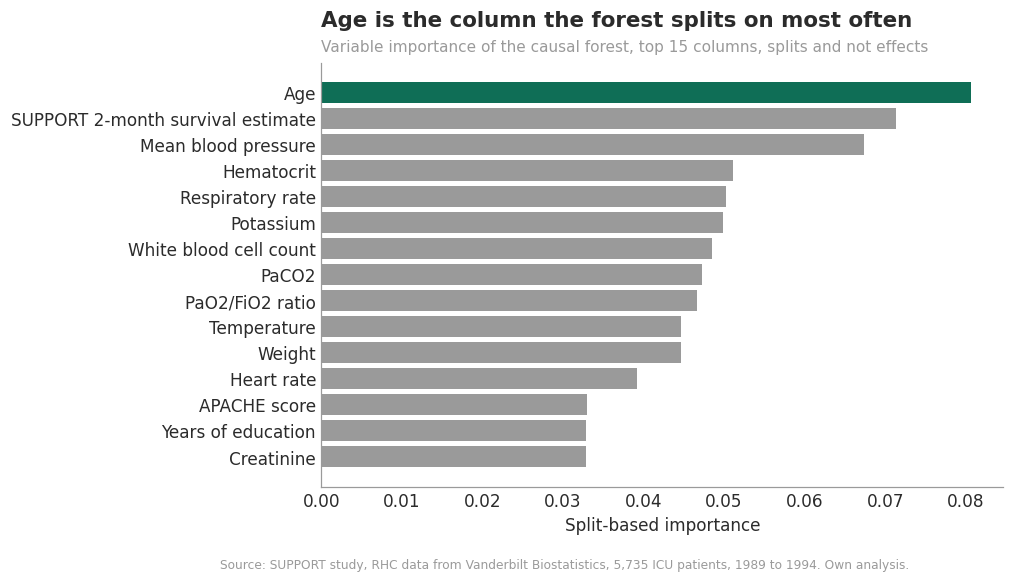

In [61]:
# [CONCEPT] Doubly robust score per patient, as in grf. Its mean is the ATE:
#           Gamma_i = tau_i + (W_i - e_i) / (e_i (1 - e_i)) * (Y_i - m_i - (W_i - e_i) tau_i)
# [WHY]     The first part is the forest's estimate for patient i, the second part corrects it with what
#           actually happened. The result stays unbiased if either the outcome or the treatment model is right
def dr_scores(W_, Y_, m_, e_, tau_):
    return tau_ + (W_ - e_) / (e_ * (1 - e_)) * (Y_ - m_ - (W_ - e_) * tau_)


# [CONCEPT] ATE, ATT and ATO are weighted means of the same scores, only the weight h(x) changes:
#           ATE: h = 1, every patient counts the same
#           ATT: h = e(x), patients who were likely to get a catheter count more
#           ATO: h = e(x)(1 - e(x)), patients for whom both decisions were realistic count most
# [WHY]     One function for all three estimands from Step 3. The standard error treats h as fixed
def weighted_effect(scores, h):
    est = np.sum(h * scores) / np.sum(h)
    influence = h * (scores - est) / h.mean()
    return est, influence.std(ddof=1) / np.sqrt(len(scores))


def effect_table(scores, e_):
    tilts = {"ATE": np.ones(len(scores)), "ATT": e_, "ATO": e_ * (1 - e_)}
    table = pd.DataFrame([(name, *weighted_effect(scores, h)) for name, h in tilts.items()],
                         columns=["estimand", "estimate", "se"]).set_index("estimand")
    table["ci_low"] = table["estimate"] - Z_CRIT * table["se"]
    table["ci_high"] = table["estimate"] + Z_CRIT * table["se"]
    return table


Gamma = dr_scores(W, Y, m_hat, e_hat, tau_hat)
cf_effects = effect_table(Gamma, e_hat)
for name, row in cf_effects.iterrows():
    print(f"Causal forest {name}: {fmt_ci(row.estimate * 100, row.ci_low * 100, row.ci_high * 100)}")
    RESULTS[f"cf_{name.lower()}"] = row.estimate
    RESULTS[f"cf_{name.lower()}_ci"] = (row.ci_low, row.ci_high)
ate_cf, se_cf = cf_effects.loc["ATE", "estimate"], cf_effects.loc["ATE", "se"]

# Which columns does the forest split on? This is how often a column is used for splits,
# not evidence that the effect varies with it. Step 8 looks at that with the best linear projection
importance = pd.Series(cf.feature_importances_, index=[col_label(c) for c in X_df.columns]).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance.index, importance.values, color=GREY)
ax.barh(importance.index[-1], importance.values[-1], color=ACCENT)
ax.set_xlabel("Split-based importance")
titles(ax, f"{importance.index[-1]} is the column the forest splits on most often",
       "Variable importance of the causal forest, top 15 columns, splits and not effects")
save(fig, "fig05a_variable_importance")

The causal forest estimates that a catheter raises 30-day mortality by 3.5 percentage points, 95% CI 1.0 to 6.1. Among patients who got a catheter the effect is 4.0 pp, in the overlap population 3.8 pp. The three estimands hardly differ, so the patients without a counterpart from Step 4 do not drive the result.

The forest splits most often on age, the SUPPORT survival estimate and blood pressure. This shows where the forest looks for differences, not whether the effect really differs. Step 8 comes back to this.

### 5.4 Estimator ladder

In [62]:
# [CONCEPT] Estimator ladder: each step uses more information than the one before
#           1. difference in means: no adjustment, valid only in a randomized trial
#           2. direct estimation: outcome model only, wrong if that model is wrong
#           3. IPW: treatment model only, wrong if that model is wrong, and unstable with extreme weights
#           4. AIPW: both models, right if either one is right
# [WHY]     If the adjusted estimators agree, the number does not hinge on one modeling choice
ladder = [("Difference in means", naive, se_naive)]   # from 1.4


def direct_effect(X_, W_, Y_):
    # g-computation: fit the outcome separately with and without a catheter, then predict every patient
    # under both treatments and average the difference
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
    mu1 = model.fit(X_[W_ == 1], Y_[W_ == 1]).predict_proba(X_)[:, 1]
    mu0 = model.fit(X_[W_ == 0], Y_[W_ == 0]).predict_proba(X_)[:, 1]
    return np.mean(mu1 - mu0)


# The direct estimate has no simple formula for its standard error, so we bootstrap it:
# draw n patients with replacement, refit, repeat N_BOOT times, take the spread of the estimates
direct = direct_effect(X, W, Y)
boot_rng = np.random.default_rng(SEED)
boot = []
for _ in range(N_BOOT):
    idx = boot_rng.integers(0, n, n)
    boot.append(direct_effect(X[idx], W[idx], Y[idx]))
ladder.append(("Direct: outcome model", direct, np.std(boot, ddof=1)))

# IPW with the stabilized weights from Step 4, robust standard error as in Hernán and Robins
ipw_fit = sm.WLS(Y, sm.add_constant(W), weights=sw).fit(cov_type="HC0")
ladder.append(("IPW: treatment model", ipw_fit.params[1], ipw_fit.bse[1]))

# Classic AIPW with the cross-fitted logistic models from 5.1:
# Gamma_i = mu1_i - mu0_i + W_i (Y_i - mu1_i) / e_i - (1 - W_i)(Y_i - mu0_i) / (1 - e_i)
G_par = mu1_par - mu0_par + W * (Y - mu1_par) / e_par - (1 - W) * (Y - mu0_par) / (1 - e_par)
ladder.append(("AIPW: logistic regression", G_par.mean(), G_par.std(ddof=1) / np.sqrt(n)))
ladder.append(("AIPW: causal forest", ate_cf, se_cf))

ladder = pd.DataFrame(ladder, columns=["estimator", "estimate", "se"]).set_index("estimator")
ladder["ci_low"] = ladder["estimate"] - Z_CRIT * ladder["se"]
ladder["ci_high"] = ladder["estimate"] + Z_CRIT * ladder["se"]
print("ATE in percentage points:")
print((ladder * 100).round(1).to_string(), "\n")
for key, name in zip(["naive", "direct", "ipw", "aipw_logit", "aipw_cf"], ladder.index):
    RESULTS[f"ate_{key}"] = ladder.loc[name, "estimate"]
    RESULTS[f"ate_{key}_ci"] = (ladder.loc[name, "ci_low"], ladder.loc[name, "ci_high"])

# The same three estimands with both sets of nuisance models
par_effects = effect_table(G_par, e_par)
by_nuisance = pd.DataFrame({"causal forest": cf_effects["estimate"], "logistic regression": par_effects["estimate"]})
print("Estimands by nuisance model, in percentage points:")
print((by_nuisance * 100).round(1).to_string())

ATE in percentage points:
                           estimate   se  ci_low  ci_high
estimator                                                
Difference in means             7.4  1.3     4.8      9.9
Direct: outcome model           6.4  1.5     3.5      9.3
IPW: treatment model            4.2  2.3    -0.4      8.8
AIPW: logistic regression       6.8  1.7     3.3     10.2
AIPW: causal forest             3.5  1.3     1.0      6.1 

Estimands by nuisance model, in percentage points:
          causal forest  logistic regression
estimand                                    
ATE                 3.5                  6.8
ATT                 4.0                  8.9
ATO                 3.8                  6.7


Every adjustment lowers the raw 7.4 pp, but by different amounts. The outcome model alone gives 6.4 pp. IPW gives 4.2 pp with an interval from −0.4 to 8.8, almost twice as wide as the causal forest's because of the extreme weights from Step 4. Estimators that rely on a single model disagree by more than 2 pp, which is why the doubly robust estimators below carry the main result.

The two AIPW estimates should agree, since both are doubly robust, but they differ by 3 pp: 3.5 with the forests and 6.8 with logistic regression. Double robustness only protects if at least one of the two models is right. Both fit about equally well in 5.1, so the data cannot tell which one is closer to the truth. The second table shows that the patients at the edge are not the reason: the ATO, which gives them almost no weight, still differs, 3.8 against 6.7 pp.

A logistic regression assumes that each covariate shifts the risk along a straight line on the log-odds scale, the forests do not. We take the causal forest as main estimate, because it assumes less about the shape of the relationships and its propensity model fits slightly better. The logistic result is a reminder that the number depends on modeling choices by about 3 pp.

### 5.5 Comparison with published estimates
Connors et al. and the trials report odds ratios. We convert them at the mortality of patients without a catheter in our data, 30.6%. The trials enrolled different patients with a different baseline risk, so the converted values are approximations.

Baseline risk for the conversion: 30.6%

                                         estimate  ci_low  ci_high
Connors et al. 1996, OR converted             4.8     0.6      9.1
Hirano and Imbens 2001, range                 5.8     5.3      6.2
13 RCTs, Shah et al. 2005, OR converted       0.8    -2.2      4.0


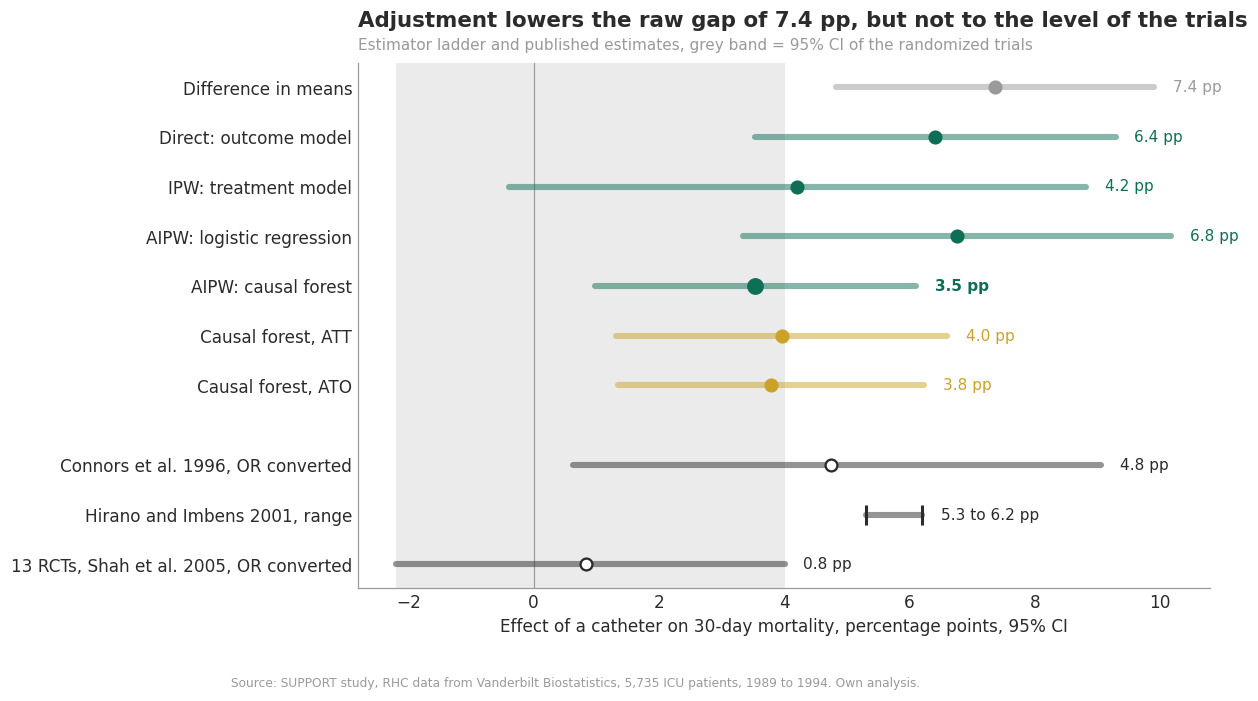

In [63]:
# [CONCEPT] Convert a published odds ratio into a risk difference at a given baseline risk p0:
#           odds1 = OR * p0 / (1 - p0), p1 = odds1 / (1 + odds1), RD = p1 - p0
# [WHY]     Con nors et al. and the trials report odds ratios, we report risk differences.
#           Example: OR 1.24 at p0 = 30.6% gives p1 = 35.3%, a risk difference of 4.7 pp
def or_to_rd(odds_ratio, p0):
    odds1 = odds_ratio * p0 / (1 - p0)
    return odds1 / (1 + odds1) - p0


p0 = Y[W == 0].mean()   # 30-day mortality without a catheter in our data
published = pd.DataFrame({
    "estimate": [or_to_rd(REF["connors_or"]["estimate"], p0), np.mean(REF["hirano_imbens_rd"]["range"]),
                 or_to_rd(REF["rct_meta_or"]["estimate"], p0)],
    "ci_low": [or_to_rd(REF["connors_or"]["ci"][0], p0), REF["hirano_imbens_rd"]["range"][0],
               or_to_rd(REF["rct_meta_or"]["ci"][0], p0)],
    "ci_high": [or_to_rd(REF["connors_or"]["ci"][1], p0), REF["hirano_imbens_rd"]["range"][1],
                or_to_rd(REF["rct_meta_or"]["ci"][1], p0)],
}, index=["Connors et al. 1996, OR converted", "Hirano and Imbens 2001, range", "13 RCTs, Shah et al. 2005, OR converted"])
print(f"Baseline risk for the conversion: {p0:.1%}\n")
print((published * 100).round(1).to_string())
RESULTS.update({"rd_connors": published.iloc[0]["estimate"], "rd_rct": published.iloc[2]["estimate"],
                "rd_rct_ci": (published.iloc[2]["ci_low"], published.iloc[2]["ci_high"])})

# Forest plot: our estimators, our three estimands, then the published values.
# The gray band marks the confidence interval of the trials
rows = pd.concat([ladder, cf_effects.loc[["ATT", "ATO"]].rename(index=lambda s: f"Causal forest, {s}"), published])
kind = ["naive", "ours", "ours", "ours", "main", "estimand", "estimand", "published", "published", "published"]
rows_pp = rows[["estimate", "ci_low", "ci_high"]] * 100
yy = np.arange(len(rows))[::-1].astype(float)
yy[-3:] -= 0.6                       # small gap before the published values

fig, ax = plt.subplots(figsize=(10, 6.2))
ax.axvspan(rows_pp.iloc[-1]["ci_low"], rows_pp.iloc[-1]["ci_high"], color=LIGHT, alpha=0.5, lw=0, zorder=0)
ax.axvline(0, color=GREY, lw=0.8)
colors = {"naive": GREY, "ours": ACCENT, "main": ACCENT, "estimand": GOLD, "published": DARK}
for yi, (name, row), k in zip(yy, rows_pp.iterrows(), kind):
    col = colors[k]
    ax.plot([row.ci_low, row.ci_high], [yi, yi], color=col, lw=4, alpha=0.5, solid_capstyle="round")
    
    if "range" in name:
        ax.scatter([row.ci_low, row.ci_high], [yi, yi], marker="|", s=160, color=col, lw=2, zorder=3)
        label = f"{row.ci_low:.1f} to {row.ci_high:.1f} pp"
    else:
        ax.scatter(row.estimate, yi, color="white" if k == "published" else col, edgecolors=col, lw=1.5,
               s=90 if k == "main" else 60, zorder=3)
        label = f"{row.estimate:.1f} pp"
    ax.text(row.ci_high + 0.3, yi, label, va="center", color=col, fontsize=10,
            fontweight="bold" if k == "main" else "normal")
    
ax.set_yticks(yy, labels=rows.index)
ax.set_xlabel("Effect of a catheter on 30-day mortality, percentage points, 95% CI")
titles(ax, f"Adjustment lowers the raw gap of {naive * 100:.1f} pp, but not to the level of the trials",
       "Estimator ladder and published estimates, grey band = 95% CI of the randomized trials")
save(fig, "fig05b_estimates")


The logistic AIPW of 6.8 pp lies close to Hirano and Imbens, 5.3 to 6.2 pp, who combined a logistic propensity score with linear regression adjustment on these data, and to Connors et al. at 4.8 pp. The causal forest gives less, 3.5 pp, but still more than the trials at 0.8 pp. Its interval overlaps with the one of the trials between 1.0 and 4.0 pp, so the two are not clearly in conflict. All adjusted estimates lie above zero.

Two explanations remain for the gap to the trials: confounding by severity that the data do not capture, and the different populations from Step 3. Step 7 asks how strong an unmeasured confounder would have to be to move our estimate to the trials.

---
## Step 6. Evaluation

The ATE is settled, now we look at the CATE. Every prediction $\hat\tau(x)$ carries noise, so the predictions vary between patients even if the true effect were the same for everyone. Three checks tell real differences from noise: the calibration test, predicted against estimated effects by quartile, and the RATE.

### 6.1 Calibration test

alpha, mean forest prediction:         1.02, 95% CI 0.30 to 1.73
beta, differential forest prediction:  0.24, 95% CI -1.46 to 1.94, one-sided p for beta > 0 = 0.390


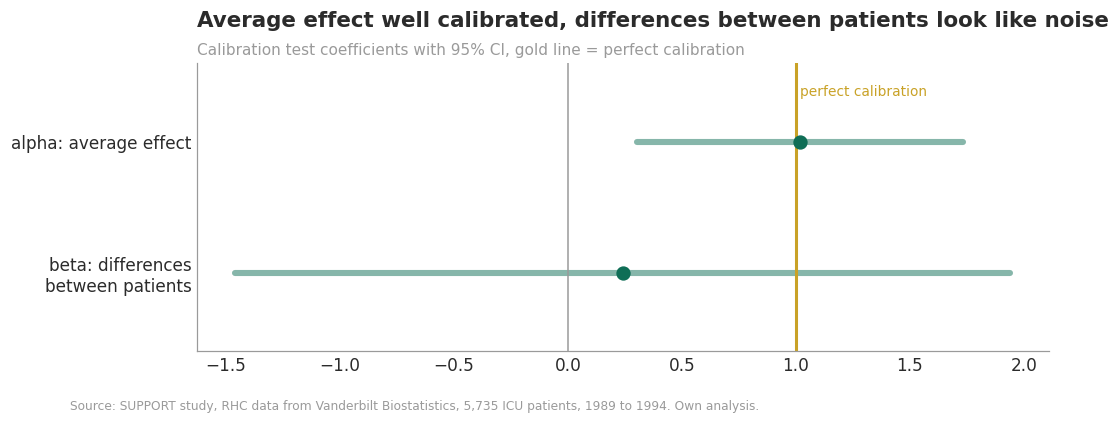

In [64]:
# [CONCEPT] Calibration test, as grf's test_calibration:
#           Y_i - m_i = alpha * C_i + beta * D_i + error, with V_i = W_i - e_i,
#           C_i = tau_bar * V_i for the average prediction and D_i = (tau_i - tau_bar) * V_i for the differences
# [WHY]     alpha close to 1: the average effect is well calibrated.
#           beta close to 1: the predicted differences between patients are right.
#           beta clearly above 0: evidence that the effect differs between patients at all
def calibration_test(W_, Y_, m_, e_, tau_):
    V = W_ - e_
    tbar = tau_.mean()
    fit = sm.OLS(Y_ - m_, np.column_stack([tbar * V, (tau_ - tbar) * V])).fit(cov_type="HC3")
    (a, b), (se_a, se_b) = fit.params, fit.bse
    return {"alpha": a, "alpha_se": se_a, "beta": b, "beta_se": se_b,
            "p_beta_gt_0": 1 - stats.norm.cdf(b / se_b)}        # one-sided, as in grf


calib = calibration_test(W, Y, m_hat, e_hat, tau_hat)
print(f"alpha, mean forest prediction:         {calib['alpha']:.2f}, 95% CI "
      f"{calib['alpha'] - Z_CRIT * calib['alpha_se']:.2f} to {calib['alpha'] + Z_CRIT * calib['alpha_se']:.2f}")
print(f"beta, differential forest prediction:  {calib['beta']:.2f}, 95% CI "
      f"{calib['beta'] - Z_CRIT * calib['beta_se']:.2f} to {calib['beta'] + Z_CRIT * calib['beta_se']:.2f}, "
      f"one-sided p for beta > 0 = {calib['p_beta_gt_0']:.3f}")
HETEROGENEITY_DETECTED = calib["p_beta_gt_0"] < ALPHA
RESULTS.update({f"calib_{k}": v for k, v in calib.items()})
RESULTS["heterogeneity_detected"] = bool(HETEROGENEITY_DETECTED)

fig, ax = plt.subplots(figsize=(10, 3.4))
coefs = [("beta: differences\nbetween patients", calib["beta"], calib["beta_se"]),
         ("alpha: average effect", calib["alpha"], calib["alpha_se"])]
for yi, (lab, est_, se_) in enumerate(coefs):
    ax.plot([est_ - Z_CRIT * se_, est_ + Z_CRIT * se_], [yi, yi], color=ACCENT, lw=4, alpha=0.5, solid_capstyle="round")
    ax.scatter(est_, yi, color=ACCENT, s=70, zorder=3)
ax.axvline(1, color=GOLD, lw=2)
ax.axvline(0, color=GREY, lw=1)
ax.text(1.02, 1.35, "perfect calibration", color=GOLD, fontsize=9)
ax.set_yticks([0, 1], labels=[c[0] for c in coefs])
ax.set_ylim(-0.6, 1.6)
alpha_ok = abs(calib["alpha"] - 1) <= Z_CRIT * calib["alpha_se"]
titles(ax, ("Average effect well calibrated, " if alpha_ok else "Average effect miscalibrated, ")
       + ("differences between patients are real" if HETEROGENEITY_DETECTED
          else "differences between patients look like noise"),
       "Calibration test coefficients with 95% CI, gold line = perfect calibration")
save(fig, "fig06a_calibration")

alpha is 1.02 with an interval from 0.30 to 1.73, consistent with a well calibrated average prediction, although the interval is wide. beta is 0.24 with an interval from −1.46 to 1.94: the predicted differences between patients cannot be told apart from noise.

### 6.2 Revise loop
A failed calibration test sends us back to Step 5. Instead of trying leaf sizes by hand, we test the whole grid from 5.2.

In [65]:
# [CONCEPT] Revise loop: a failed calibration test sends us back to Step 5
# [WHY]     Instead of trying leaf sizes by hand, we test the whole grid from 5.2 at once
revise = pd.DataFrame({
    leaf: {"R-loss": f["r_loss"],
           **{k: v for k, v in calibration_test(W, Y, m_hat, e_hat, f["tau"]).items()
              if k in ("alpha", "beta", "beta_se", "p_beta_gt_0")}}
    for leaf, f in forests.items()}).T
revise.index.name = "min_samples_leaf"
print(revise.round(3).to_string(), "\n")

if abs(calib["alpha"] - 1) > Z_CRIT * calib["alpha_se"]:
    print("alpha differs from 1: the average effect is miscalibrated. Revisit the nuisance models in 5.1.")
if calib["beta"] < 0:
    print("beta < 0 for the selected forest: its ranking points the wrong way. Try larger leaves in 5.2.")
if not (revise["p_beta_gt_0"] < ALPHA).any():
    print("beta is not significantly above 0 for any leaf size: the data cannot confirm that the effect differs.\n"
          "This is a result, not a bug. Every CATE figure below is exploratory.")

                  R-loss  alpha   beta  beta_se  p_beta_gt_0
min_samples_leaf                                            
5                  0.181  1.033  0.156    0.466        0.369
10                 0.181  1.034 -0.288    0.586        0.689
20                 0.181  1.026 -0.143    0.705        0.580
40                 0.181  1.017  0.241    0.868        0.390 

beta is not significantly above 0 for any leaf size: the data cannot confirm that the effect differs.
This is a result, not a bug. Every CATE figure below is exploratory.


No leaf size gives a beta clearly above 0, two even give a negative one. The problem is not the tuning. With 5,735 patients and a 0/1 outcome, differences of a few percentage points between patients are hard to detect, and Step 7.3 shows how hard.

### 6.3 Predicted against estimated effects
We group patients by their predicted effect and estimate each group's effect with the doubly robust scores. If the forest's differences are real, the estimated effects per quartile rise from the first to the fourth quartile.

             predicted  estimated   se
quartile                              
Q1, lowest         1.8        7.4  2.9
Q2                 3.2       -1.6  2.4
Q3                 4.2        3.8  2.7
Q4, highest        5.6        4.6  2.4

Q4 minus Q1, estimated: -2.8 pp, 95% CI -10.3 to 4.6


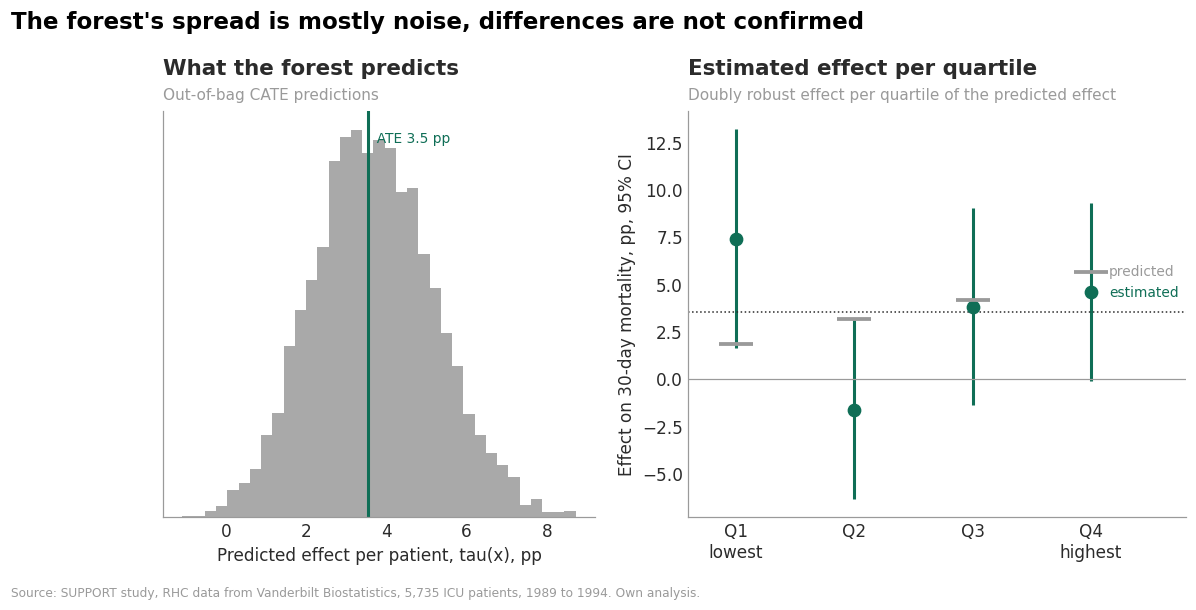

In [66]:
# [CONCEPT] Group patients by their predicted effect and estimate each group's effect with the doubly robust scores
# [WHY]     The forest's predictions always vary, even if the true effect is the same for everyone.
#           If the differences are real, the estimated effects rise from the first to the fourth quartile
quartile = pd.qcut(tau_hat, 4, labels=["Q1, lowest", "Q2", "Q3", "Q4, highest"])
q_tab = (pd.DataFrame({"quartile": quartile, "Gamma": Gamma, "tau": tau_hat})
         .groupby("quartile", observed=True)
         .agg(predicted=("tau", "mean"), estimated=("Gamma", "mean"),
              se=("Gamma", lambda g: g.std(ddof=1) / np.sqrt(len(g)))))
q_diff = q_tab["estimated"].iloc[-1] - q_tab["estimated"].iloc[0]
q_diff_se = np.sqrt(q_tab["se"].iloc[-1] ** 2 + q_tab["se"].iloc[0] ** 2)
print((q_tab * 100).round(1).to_string())
print(f"\nQ4 minus Q1, estimated: {fmt_ci(q_diff * 100, (q_diff - Z_CRIT * q_diff_se) * 100, (q_diff + Z_CRIT * q_diff_se) * 100)}")
RESULTS.update({"q4_minus_q1": q_diff, "q4_minus_q1_se": q_diff_se})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
ax.hist(tau_hat * 100, bins=35, color=GREY, alpha=0.85)
ax.axvline(ate_cf * 100, color=ACCENT, lw=2)
ax.text(ate_cf * 100, ax.get_ylim()[1] * 0.95, f"  ATE {ate_cf * 100:.1f} pp", color=ACCENT, fontsize=9, va="top")
ax.set_xlabel("Predicted effect per patient, tau(x), pp")
ax.set_yticks([])
titles(ax, "What the forest predicts", "Out-of-bag CATE predictions")
ax = axes[1]
xq = np.arange(len(q_tab))
ax.errorbar(xq, q_tab["estimated"] * 100, yerr=Z_CRIT * q_tab["se"] * 100, fmt="o", color=ACCENT, ms=8, lw=2, capsize=0)
ax.scatter(xq, q_tab["predicted"] * 100, marker="_", s=500, color=GREY, lw=2.5, zorder=3)
ax.axhline(ate_cf * 100, color=DARK, ls=":", lw=1)
ax.axhline(0, color=GREY, lw=0.8)
ax.text(xq[-1] + 0.15, q_tab["predicted"].iloc[-1] * 100, "predicted", color=GREY, fontsize=9, va="center")
ax.text(xq[-1] + 0.15, q_tab["estimated"].iloc[-1] * 100, "estimated", color=ACCENT, fontsize=9, va="center")
ax.set_xlim(-0.4, xq[-1] + 0.8)
ax.set_xticks(xq, labels=[lab.replace(", ", "\n") for lab in q_tab.index])
ax.set_ylabel("Effect on 30-day mortality, pp, 95% CI")
titles(ax, "Estimated effect per quartile", "Doubly robust effect per quartile of the predicted effect")
fig.suptitle("Patients predicted to be harmed more are harmed more" if HETEROGENEITY_DETECTED
             else "The forest's spread is mostly noise, differences are not confirmed",
             x=0.01, ha="left", fontweight="bold", fontsize=15, y=1.07)
save(fig, "fig06b_heterogeneity_check")

The forest predicts effects from 1.8 pp in the lowest to 5.6 pp in the highest quartile. The estimated effects per quartile do not follow this order: 7.4, −1.6, 3.8 and 4.6 pp, each with an interval of about ±5 pp. The highest quartile minus the lowest gives −2.8 pp, 95% CI −10.3 to 4.6.

### 6.4 RATE: can we rank patients by their effect?
We learn a ranking on one half of the patients and evaluate it on the other half. As a simple alternative that needs no model, we rank by the APACHE score, sickest first.

causal forest   RATE = 2.3 pp, 95% CI -1.1 to 5.8
APACHE score    RATE = 2.6 pp, 95% CI -0.9 to 6.2


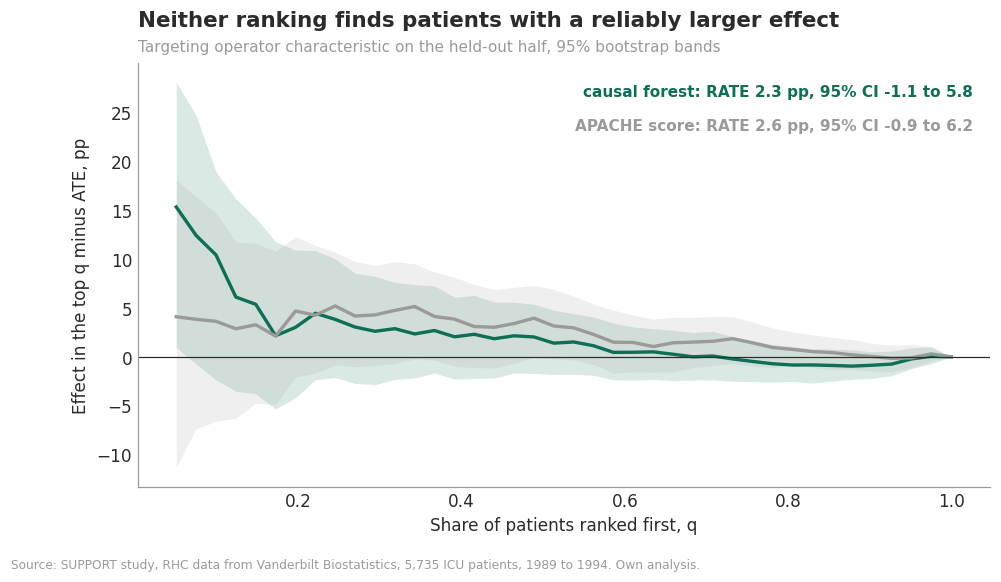

In [67]:
# [CONCEPT] RATE with split and score: learn a ranking on one half of the patients,
#           rank the other half with it and evaluate there with that half's doubly robust scores
#           TOC(q) = effect among the top q of the ranking minus the ATE, AUTOC = area under TOC = RATE
# [WHY]     If the same data rank and evaluate, noise looks like signal. Splitting keeps it honest
idx_tr, idx_ev = train_test_split(np.arange(n), test_size=0.5, stratify=W, random_state=SEED)

# Training half: learn the ranking rule tau_train(x)
m_tr, e_tr = fit_m_hat(X[idx_tr], Y[idx_tr]), fit_e_hat(X[idx_tr], W[idx_tr])
cf_tr, _ = fit_causal_forest(X[idx_tr], W[idx_tr], Y[idx_tr], m_tr, e_tr, BEST_LEAF)

# Evaluation half: doubly robust scores from models fitted on this half only
m_ev, e_ev = fit_m_hat(X[idx_ev], Y[idx_ev]), fit_e_hat(X[idx_ev], W[idx_ev])
_, tau_ev = fit_causal_forest(X[idx_ev], W[idx_ev], Y[idx_ev], m_ev, e_ev, BEST_LEAF)
G_ev = dr_scores(W[idx_ev], Y[idx_ev], m_ev, e_ev, tau_ev)

Q_GRID = np.linspace(0.05, 1.0, 40)   # the top 5% are too few patients to show reliably


def toc_curve(S, G):
    # Sort by priority S, highest first, then the running mean of the scores minus the overall mean
    order = np.argsort(-S, kind="stable")
    k = np.arange(1, len(G) + 1)
    return k / len(G), np.cumsum(G[order]) / k - G.mean()


def rate(S, G, n_boot=N_BOOT_RATE, seed=SEED):
    r_ = np.random.default_rng(seed)
    q, toc = toc_curve(S, G)
    grid_idx = np.ceil(Q_GRID * len(G)).astype(int) - 1
    boot_autoc, boot_curves = [], []
    for _ in range(n_boot):                       # bootstrap the evaluation half
        i = r_.integers(0, len(G), len(G))
        _, tb = toc_curve(S[i], G[i])
        boot_autoc.append(tb.mean())
        boot_curves.append(tb[grid_idx])
    band = np.percentile(boot_curves, [2.5, 97.5], axis=0)
    return {"q": q, "toc": toc, "autoc": toc.mean(), "se": np.std(boot_autoc, ddof=1),
            "band": band, "toc_grid": toc[grid_idx]}


# Two rankings: the causal forest, and a simple rule a physician could apply without a model,
# the sickest patients first. The APACHE score has many ties, so a tiny random number breaks them
tie_breaker = rng.normal(0, 1e-6, len(idx_ev))
priority_rules = {"causal forest": cf_tr.predict(X[idx_ev]).ravel(),
                  "APACHE score": X_df["aps1"].to_numpy(dtype=float)[idx_ev] + tie_breaker}
rate_res = {name: rate(S, G_ev) for name, S in priority_rules.items()}
for name, rr in rate_res.items():
    print(f"{name:15s} RATE = {fmt_ci(rr['autoc'] * 100, (rr['autoc'] - Z_CRIT * rr['se']) * 100, (rr['autoc'] + Z_CRIT * rr['se']) * 100)}")
    RESULTS[f"rate_{name.replace(' ', '_').lower()}"] = rr["autoc"]
    RESULTS[f"rate_{name.replace(' ', '_').lower()}_se"] = rr["se"]

fig, ax = plt.subplots(figsize=(10, 5))
for i, ((name, rr), col) in enumerate(zip(rate_res.items(), [ACCENT, GREY])):
    ax.fill_between(Q_GRID, rr["band"][0] * 100, rr["band"][1] * 100, color=col, alpha=0.15, lw=0)
    ax.plot(Q_GRID, rr["toc_grid"] * 100, color=col, lw=2.2)
    ax.text(0.98, 0.95 - 0.08 * i, f"{name}: RATE " + fmt_ci(rr["autoc"] * 100, (rr["autoc"] - Z_CRIT * rr["se"]) * 100,
            (rr["autoc"] + Z_CRIT * rr["se"]) * 100), transform=ax.transAxes, ha="right", va="top",
            color=col, fontsize=10, fontweight="bold")
ax.axhline(0, color=DARK, lw=0.8)
ax.set_xlabel("Share of patients ranked first, q")
ax.set_ylabel("Effect in the top q minus ATE, pp")
any_sig = any(rr["autoc"] - Z_CRIT * rr["se"] > 0 for rr in rate_res.values())
titles(ax, "A ranking finds patients with a larger effect" if any_sig
       else "Neither ranking finds patients with a reliably larger effect",
       "Targeting operator characteristic on the held-out half, 95% bootstrap bands")
save(fig, "fig06c_rate_toc")

Both rankings put patients with a somewhat larger effect first, by 2.3 pp for the forest and 2.6 pp for the APACHE score, but both intervals include zero. The simple ranking by severity does at least as well as the forest.

Three checks, one answer: the data cannot distinguish the effect between patients. This is a result, not a failure, and every figure in Step 8 should be read with it in mind.

---
## Step 7. Robustness

| Check | Idea | Passes if |
|---|---|---|
| 7.1 Placebo treatment | shuffle W randomly | the placebo effects are about 0 and the real one stands out |
| 7.2 Random common cause | add a column of pure noise | the estimate does not move |
| 7.3 Semi-synthetic outcome | real X and W, synthetic Y with a known effect | the pipeline recovers the truth |
| 7.4 Unmeasured confounding | how strong would a hidden confounder have to be? | stronger than the measured confounder groups |
| 7.5 Specification | trimming and the choice of nuisance models | the estimate moves by less than one standard error |

All refits use the pipeline from Step 5 with lighter forests, `N_TREES_REFUTE`, and are compared with a baseline refit with the same settings.

In [68]:
# [CONCEPT] The whole pipeline from Step 5 in one function: nuisances, causal forest, doubly robust ATE
# [WHY]     Every check in Step 7 changes one thing and reruns everything else. Lighter forests keep it fast,
#           so all checks compare against a baseline refit with exactly the same settings.
#           m or e can be passed in when the manipulation cannot change them, which saves time
def cf_pipeline(X_, W_, Y_, m_=None, e_=None, n_trees=N_TREES_REFUTE, seed=SEED):
    m_ = fit_m_hat(X_, Y_, n_trees, seed) if m_ is None else m_
    e_ = fit_e_hat(X_, W_, n_trees, seed) if e_ is None else e_
    cf_, tau_ = fit_causal_forest(X_, W_, Y_, m_, e_, BEST_LEAF, n_trees, seed)
    G_ = dr_scores(W_, Y_, m_, e_, tau_)
    return {"ate": G_.mean(), "se": G_.std(ddof=1) / np.sqrt(len(G_)), "tau": tau_, "cf": cf_,
            "m": m_, "e": e_, "G": G_}


base = cf_pipeline(X, W, Y)
print(f"Baseline refit with {N_TREES_REFUTE} trees: ATE = {base['ate'] * 100:.1f} pp, se {base['se'] * 100:.1f} pp")

Baseline refit with 1000 trees: ATE = 3.6 pp, se 1.3 pp


### 7.1 Placebo treatment

Placebo effects: mean -0.15 pp, sd 1.13 pp, permutation p-value of the real effect = 0.048
Placebo check passed.


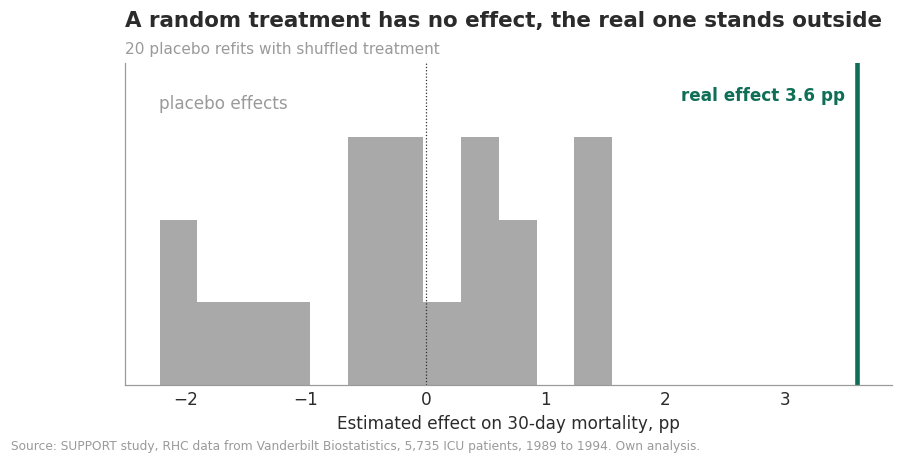

In [69]:
# [CONCEPT] Placebo treatment: shuffle W randomly and rerun the pipeline
# [WHY]     A shuffled catheter cannot cause anything. If the pipeline still finds an effect, it manufactures
#           effects out of the covariates, and no other number can be trusted.
#           m(x) = E[Y | X] does not depend on W, so it is reused. e(x) has to be refitted
placebo_ates = np.array([cf_pipeline(X, W_perm, Y, m_=base["m"])["ate"]
                         for W_perm in (rng.permutation(W) for _ in range(N_PLACEBO))])

# Permutation p-value: the share of placebo effects at least as large as the real one, smallest possible 1 / 21
p_placebo = (np.sum(np.abs(placebo_ates) >= abs(base["ate"])) + 1) / (N_PLACEBO + 1)
# t-test: is the mean of the placebo effects distinguishable from 0?
t_placebo = placebo_ates.mean() / (placebo_ates.std(ddof=1) / np.sqrt(N_PLACEBO))
PLACEBO_OK = bool((np.abs(placebo_ates) < abs(base["ate"])).all()
                  and abs(t_placebo) < stats.t.ppf(1 - ALPHA / 2, N_PLACEBO - 1))
print(f"Placebo effects: mean {placebo_ates.mean() * 100:+.2f} pp, sd {placebo_ates.std(ddof=1) * 100:.2f} pp, "
      f"permutation p-value of the real effect = {p_placebo:.3f}")
print("Placebo check passed." if PLACEBO_OK else "Placebo check failed: go back to the assumptions in Step 4.")
RESULTS.update({"placebo_mean": placebo_ates.mean(), "placebo_sd": placebo_ates.std(ddof=1), "placebo_p": p_placebo})

fig, ax = plt.subplots(figsize=(9, 3.8))
counts, _, _ = ax.hist(placebo_ates * 100, bins=12, color=GREY, alpha=0.85)
ax.set_ylim(0, counts.max() * 1.3)
ax.axvline(base["ate"] * 100, color=ACCENT, lw=3)
ax.text(base["ate"] * 100, counts.max() * 1.15, f"real effect {base['ate'] * 100:.1f} pp  ", color=ACCENT,
        fontweight="bold", ha="right")
ax.text(np.percentile(placebo_ates, 10) * 100, counts.max() * 1.1, "placebo effects", color=GREY, ha="center", va="bottom")
ax.axvline(0, color=DARK, lw=0.8, ls=":")
ax.set_yticks([])
ax.set_xlabel("Estimated effect on 30-day mortality, pp")
titles(ax, "A random treatment has no effect, the real one stands outside" if PLACEBO_OK
       else "Warning: the pipeline finds effects of a random treatment",
       f"{N_PLACEBO} placebo refits with shuffled treatment")
save(fig, "fig07a_placebo")

The 20 placebo effects scatter around −0.15 pp with a standard deviation of 1.1 pp, and none comes close to the real 3.6 pp. The permutation p-value of 0.048 is the smallest possible with 20 refits. The pipeline does not invent effects out of the covariates.

### 7.2 Random common cause

In [70]:
# [CONCEPT] Random common cause: add a column of pure noise to X and rerun
# [WHY]     Adjusting for a variable that is unrelated to everything must not change the answer.
#           The rank of the noise column in the importance list also shows how arbitrary the splits are
rcc = []
for r in range(N_RCC):
    X_noise = np.column_stack([X, rng.normal(size=n)])
    res = cf_pipeline(X_noise, W, Y)
    imp = res["cf"].feature_importances_
    rcc.append({"ate, pp": res["ate"] * 100, "importance of noise": imp[-1],
                f"rank of noise, 1 = top of {X_noise.shape[1]}": int((imp > imp[-1]).sum() + 1)})
rcc = pd.DataFrame(rcc)
rcc_shift = (rcc["ate, pp"] / 100 - base["ate"]).abs().max()
RCC_OK = rcc_shift < 0.5 * base["se"]
print(rcc.round(3).to_string())
print(f"\nLargest shift of the ATE: {rcc_shift * 100:.2f} pp, threshold is half a standard error = {0.5 * base['se'] * 100:.2f} pp")
print("Random common cause check passed." if RCC_OK else "The estimate reacts to noise: check the stability of the forest.")
RESULTS.update({"rcc_max_shift": rcc_shift})

   ate, pp  importance of noise  rank of noise, 1 = top of 71
0    3.749                0.047                             7
1    3.471                0.045                             7
2    3.516                0.053                             4
3    3.520                0.056                             4
4    3.494                0.059                             4
5    3.630                0.058                             4
6    3.520                0.050                             4
7    3.402                0.059                             4
8    3.655                0.046                             8
9    3.295                0.049                             6

Largest shift of the ATE: 0.30 pp, threshold is half a standard error = 0.66 pp
Random common cause check passed.


The ATE moves by at most 0.30 pp over 10 refits, below half a standard error. More telling is the importance list: the noise column ranks between 4th and 8th of 71. The forest splits on noise about as often as on hematocrit or potassium, and more often than on the APACHE score, one more sign that its splits carry little information about differences in the effect, as Step 6 found.

### 7.3 Semi-synthetic outcome
We keep the real covariates and the real catheter decisions but draw a new outcome with a known effect. The risk without a catheter is $m(x)$ from 5.1, so catheter patients are sicker exactly as in the real data. Scenario 1 has no effect at all. Scenario 2 has an average effect of 3.5 pp that grows by 4 pp per standard deviation of the APACHE score, about 2 pp per 10 points.

scenario        no effect  effect grows with severity
true_ate             0.00                        3.51
naive                4.17                        8.39
estimate             0.91                        4.07
coverage             0.95                        1.00
share_beta_sig       0.05                        0.25
true_slope           0.00                        1.99
blp_slope           -0.10                        1.39
share_blp_sig        0.10                        0.40
bias                 0.91                        0.56 

Bias test, no effect: t = 3.06, systematic bias


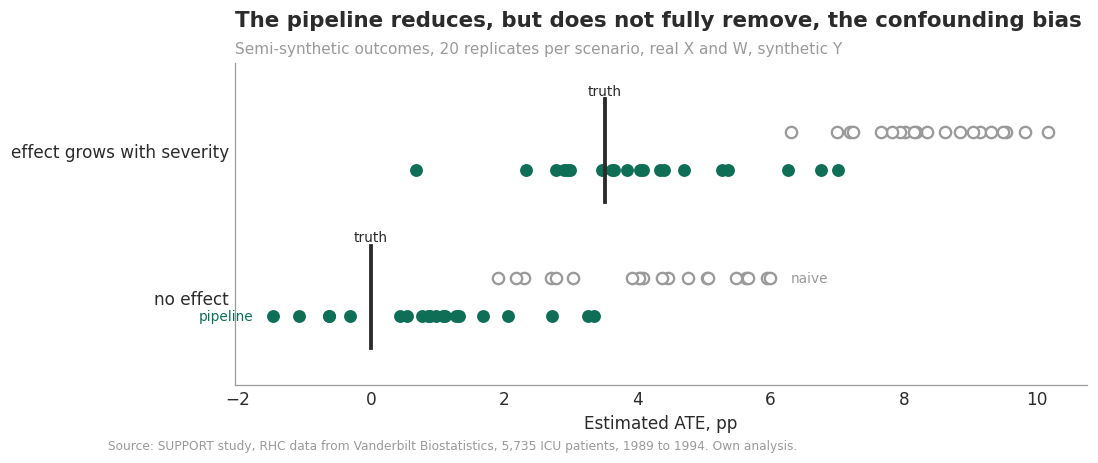

In [71]:
# [CONCEPT] Semi-synthetic outcome: keep the real X and the real, confounded W, but draw a new Y
#           with a known effect: P(Y = 1) = p0(x) + W * tau_true(x)
#           p0(x) = m_hat(x), the real relation between the covariates and mortality from 5.1
# [WHY]     The only test in which we know the right answer. Scenario 1 has no effect at all and checks
#           whether confounding by the measured covariates fools the pipeline. Scenario 2 has an effect
#           that grows with severity and checks whether the pipeline would find such differences
p0 = m_hat     # catheter patients have a higher p0, so the naive comparison is confounded as in the real data
aps_z = ((df["aps1"] - df["aps1"].mean()) / df["aps1"].std()).to_numpy()
scenarios = {"no effect": np.zeros(n),
             "effect grows with severity": 0.035 + 0.04 * aps_z}   # 3.5 pp on average, 4 pp more per SD of APACHE
aps10 = df["aps1"].to_numpy() / 10

rows = []
for name, tau_raw in scenarios.items():
    p1 = np.clip(p0 + tau_raw, 0, 1)
    tau_true = p1 - p0                                             # the effect after clipping to valid probabilities
    true_slope = np.polyfit(aps10, tau_true, 1)[0]                 # change per 10 APACHE points
    for r in range(N_SEMISYNTH):
        Y_syn = rng.binomial(1, np.where(W == 1, p1, p0)).astype(float)
        res = cf_pipeline(X, W, Y_syn, e_=base["e"])               # e(x) does not depend on Y: reuse it
        cal = calibration_test(W, Y_syn, res["m"], res["e"], res["tau"])
        blp_s = sm.OLS(res["G"], sm.add_constant(aps10)).fit(cov_type="HC3")
        rows.append({"scenario": name, "true_ate": tau_true.mean(),
                     "naive": Y_syn[W == 1].mean() - Y_syn[W == 0].mean(),
                     "estimate": res["ate"], "covered": abs(res["ate"] - tau_true.mean()) <= Z_CRIT * res["se"],
                     "beta_significant": cal["p_beta_gt_0"] < ALPHA,
                     "blp_slope": blp_s.params[1], "blp_significant": blp_s.pvalues[1] < ALPHA,
                     "true_slope": true_slope})
semi = pd.DataFrame(rows)
semi_summary = semi.groupby("scenario", sort=False).agg(
    true_ate=("true_ate", "mean"), naive=("naive", "mean"), estimate=("estimate", "mean"),
    coverage=("covered", "mean"), share_beta_sig=("beta_significant", "mean"),
    true_slope=("true_slope", "mean"), blp_slope=("blp_slope", "mean"), share_blp_sig=("blp_significant", "mean"))
semi_summary["bias"] = semi_summary["estimate"] - semi_summary["true_ate"]

# Is the bias in the scenario without effect distinguishable from 0? t-test over the replicates
s1 = semi[semi["scenario"] == "no effect"]
t_bias = s1["estimate"].mean() / (s1["estimate"].std(ddof=1) / np.sqrt(len(s1)))
SEMI_OK = abs(t_bias) < stats.t.ppf(1 - ALPHA / 2, len(s1) - 1)
pp_cols = ["true_ate", "naive", "estimate", "bias", "true_slope", "blp_slope"]
print((semi_summary.assign(**{c: semi_summary[c] * 100 for c in pp_cols})).round(2).T.to_string(), "\n")
print(f"Bias test, no effect: t = {t_bias:.2f}, " + ("no detectable bias" if SEMI_OK else "systematic bias"))
RESULTS.update({"semi_bias_no_effect": semi_summary.loc["no effect", "bias"],
                "semi_naive_no_effect": semi_summary.loc["no effect", "naive"],
                "semi_power_beta": semi_summary.loc["effect grows with severity", "share_beta_sig"],
                "semi_power_blp": semi_summary.loc["effect grows with severity", "share_blp_sig"]})

fig, ax = plt.subplots(figsize=(10, 3.8))
for yi, (name, grp) in enumerate(semi.groupby("scenario", sort=False)):
    ax.scatter(grp["naive"] * 100, np.full(len(grp), yi + 0.13), facecolors="white", edgecolors=GREY, s=55, lw=1.5)
    ax.scatter(grp["estimate"] * 100, np.full(len(grp), yi - 0.13), color=ACCENT, s=55)
    ax.plot([grp["true_ate"].iloc[0] * 100] * 2, [yi - 0.35, yi + 0.35], color=DARK, lw=2.5)
    ax.text(grp["true_ate"].iloc[0] * 100, yi + 0.38, "truth", ha="center", fontsize=9, color=DARK)
ax.text(semi.loc[semi["scenario"] == "no effect", "naive"].max() * 100 + 0.3, 0.13, "naive", color=GREY,
        fontsize=9, va="center")
ax.text(semi.loc[semi["scenario"] == "no effect", "estimate"].min() * 100 - 0.3, -0.13, "pipeline",
        color=ACCENT, fontsize=9, ha="right", va="center")
ax.set_yticks(range(len(scenarios)), labels=list(scenarios))
ax.set_ylim(-0.6, len(scenarios) - 0.4)
ax.set_xlabel("Estimated ATE, pp")
titles(ax, "With a known effect, the pipeline comes close to the truth and the naive comparison does not" if SEMI_OK
       else "The pipeline reduces, but does not fully remove, the confounding bias",
       f"Semi-synthetic outcomes, {N_SEMISYNTH} replicates per scenario, real X and W, synthetic Y")
save(fig, "fig07b_semisynthetic")

Without any effect, the naive comparison finds 4.2 pp, simply because catheter patients were sicker. The pipeline brings this down to 0.9 pp, so it removes about 78% of the bias but not all of it. Over 20 replicates the mean estimate is +0.91 pp, t = 3.06, a systematic bias with a 95% interval of roughly 0.3 to 1.5 pp. The interval covers the truth in 19 of 20 replicates, which hides the bias because the intervals are wide. With an effect of 3.5 pp that grows with severity, the pipeline estimates 4.1 pp, with coverage in 20 of 20 replicates. The remaining positive bias, 0.9 pp without an effect and 0.6 pp with one, suggests that the main estimate of 3.5 pp may be somewhat too high, although the simulation favors forest nuisance models and the bias in the real data is unknown.

The second scenario also shows the limits from Step 6. The calibration test detects the built-in differences in 5 of 20 replicates. The best linear projection on the APACHE score finds the direction but underestimates the true slope of 2.0 pp per 10 points, 1.4 against 2.0, and finds it significant in 8 of 20 replicates. So differences of this size would often go undetected, and the null result in Step 6 does not mean the effect is the same for everyone.

### 7.4 Sensitivity to unmeasured confounding
Unconfoundedness cannot be tested. Instead we ask how strong a hidden confounder would have to be to move our estimate to zero or to the level of the trials, and compare it with the confounder groups from Step 2. The framework by Cinelli and Hazlett needs a linear model, so it works with a linear probability model. Its estimate is larger than the causal forest's, so we also print an approximate value for the forest.

In [72]:
# [CONCEPT] Omitted variable bias in partial R2 terms, Cinelli and Hazlett 2020:
#           |bias| = se * sqrt(df) * sqrt( R2(Y~U | W,X) * R2(W~U | X) / (1 - R2(W~U | X)) )
# [WHY]     It turns "how strong would U have to be?" into two shares of explained variance, one for the
#           catheter and one for death, which can be compared with covariates we did measure.
#           The framework needs a linear model, so we use a linear probability model: OLS of Y on W and X
design_y = sm.add_constant(np.column_stack([W, X]))   # columns: constant, W, then the 70 columns of X
design_w = sm.add_constant(X)                          # columns: constant, then the 70 columns of X
lin = sm.OLS(Y, design_y).fit()
est, se_lin, dof = lin.params[1], lin.bse[1], lin.df_resid
t_stat = est / se_lin
rd_rct = RESULTS["rd_rct"]                             # the trials' effect, converted in 5.5


def robustness_value(t, dof, q=1.0, alpha=None):
    # Partial R2 that U needs with BOTH W and Y to reduce the estimate by the share q.
    # q = 1 erases it, q = 0.5 halves it. With alpha, the version that makes it insignificant
    f = q * abs(t) / np.sqrt(dof)                      # Cohen's f of the treatment, scaled by q
    if alpha is not None:
        f -= abs(stats.t.ppf(alpha / 2, dof - 1)) / np.sqrt(dof - 1)
        if f <= 0:
            return 0.0
    return 0.5 * (np.sqrt(f ** 4 + 4 * f ** 2) - f ** 2)


def bias(r2_yu, r2_wu):
    return se_lin * np.sqrt(dof) * np.sqrt(r2_yu * r2_wu / (1 - r2_wu))


q_rct = (est - rd_rct) / est                           # share of the estimate U must explain to reach the trials
rv, rv_alpha, rv_rct = robustness_value(t_stat, dof), robustness_value(t_stat, dof, alpha=ALPHA), \
    robustness_value(t_stat, dof, q=q_rct)
assert np.isclose(bias(rv, rv), abs(est)), "self-check: a confounder of strength RV must erase the estimate"
print(f"Linear probability model: {fmt_ci(est * 100, (est - Z_CRIT * se_lin) * 100, (est + Z_CRIT * se_lin) * 100)}")
print(f"RV to erase the effect:             {rv:.1%} of the remaining variance of both W and Y")
print(f"RV to make it insignificant at 5%:  {rv_alpha:.1%}")
print(f"RV to move it to the trials, {rd_rct * 100:.1f} pp: {rv_rct:.1%}")
# The same formula with the t-statistic of the causal forest, as a rough guide for the main estimate
rv_cf = robustness_value(ate_cf / se_cf, dof)
print(f"RV to erase the causal forest ATE, approximate: {rv_cf:.1%}\n")


def partial_r2(y, design, drop):
    # Share of the remaining variance that the dropped columns explain, from a nested model comparison
    full = sm.OLS(y, design).fit()
    reduced = sm.OLS(y, np.delete(design, drop, axis=1)).fit()
    return (reduced.ssr - full.ssr) / reduced.ssr


def benchmark_bound(r2_wxj, r2_yxj, k):
    # Strength of a U that is k times as strong as the covariate X_j, Cinelli and Hazlett 2020, section 6
    if k * r2_wxj >= 1:
        return None
    r2_wu = k * r2_wxj / (1 - r2_wxj)
    r2_uxj = k * r2_wxj ** 2 / ((1 - k * r2_wxj) * (1 - r2_wxj))
    if r2_uxj >= 1 or r2_wu >= 1:
        return None
    r2_yu = ((np.sqrt(k) + np.sqrt(r2_uxj)) / np.sqrt(1 - r2_uxj)) ** 2 * (r2_yxj / (1 - r2_yxj))
    return min(r2_yu, 1.0), r2_wu


def k_to_reach(r2_wxj, r2_yxj, target, ks=np.arange(0.1, 100.01, 0.1)):
    # Smallest multiple k of the benchmark's strength that pushes the estimate down to the target
    for k in ks:
        bb = benchmark_bound(r2_wxj, r2_yxj, k)
        if bb is None:
            return np.nan
        if est - bias(*bb) <= target:
            return k
    return np.inf


# Benchmarks: the three strongest confounder groups from Step 2. A single column like the APACHE score is a poor
# benchmark here, because the physiology columns it is built from already explain most of it.
# Column positions in X, +1 for the constant in design_w and +2 for the constant and W in design_y
BENCHMARKS = {group.lower(): group_columns(CONFOUNDER_GROUPS[group])
              for group in ["Diagnosis", "Severity scores", "Physiology and labs"]}
sens_rows, k_erase, k_rct = [], {}, {}
for label, cols in BENCHMARKS.items():
    j = [X_df.columns.get_loc(c) for c in cols]
    r2_wxj = partial_r2(W, design_w, [i + 1 for i in j])
    r2_yxj = partial_r2(Y, design_y, [i + 2 for i in j])
    k_erase[label], k_rct[label] = k_to_reach(r2_wxj, r2_yxj, 0.0), k_to_reach(r2_wxj, r2_yxj, rd_rct)
    for k in (1, 2, 3):
        r2_yu, r2_wu = benchmark_bound(r2_wxj, r2_yxj, k)
        adj = est - bias(r2_yu, r2_wu)
        adj_se = se_lin * np.sqrt((1 - r2_yu) / (1 - r2_wu)) * np.sqrt(dof / (dof - 1))
        sens_rows.append({"benchmark": f"{k}x {label}", "k": k, "R2(W~U|X)": r2_wu, "R2(Y~U|W,X)": r2_yu,
                          "adjusted, pp": adj * 100, "ci_low, pp": (adj - Z_CRIT * adj_se) * 100,
                          "ci_high, pp": (adj + Z_CRIT * adj_se) * 100})
sens = pd.DataFrame(sens_rows).set_index("benchmark")
SENS_OK = bool((sens.loc[sens["k"] == 1, "ci_low, pp"] > 0).all())
print(sens.drop(columns="k").round(3).to_string())
print("\nHow many times as strong as the benchmark must U be")
print("  to erase the effect:      ", {k_: float(np.round(v, 1)) for k_, v in k_erase.items()})
print("  to reach the trials:      ", {k_: float(np.round(v, 1)) for k_, v in k_rct.items()})
RESULTS.update({"sens_estimate_linear": est, "sens_rv": rv, "sens_rv_alpha": rv_alpha, "sens_rv_rct": rv_rct,
                "sens_rv_cf_approx": rv_cf,
                **{f"sens_k_erase_{k_.replace(' ', '_')}": v for k_, v in k_erase.items()},
                **{f"sens_k_rct_{k_.replace(' ', '_')}": v for k_, v in k_rct.items()}})

Linear probability model: 6.2 pp, 95% CI 3.6 to 8.8
RV to erase the effect:             6.1% of the remaining variance of both W and Y
RV to make it insignificant at 5%:  3.6%
RV to move it to the trials, 0.8 pp: 5.3%
RV to erase the causal forest ATE, approximate: 3.5%

                        R2(W~U|X)  R2(Y~U|W,X)  adjusted, pp  ci_low, pp  ci_high, pp
benchmark                                                                            
1x diagnosis                0.072        0.028         1.619      -1.030        4.267
2x diagnosis                0.145        0.056        -3.424      -6.142       -0.706
3x diagnosis                0.217        0.085        -9.001     -11.798       -6.205
1x severity scores          0.011        0.026         4.553       1.986        7.119
2x severity scores          0.021        0.053         2.861       0.316        5.406
3x severity scores          0.032        0.079         1.150      -1.373        3.674
1x physiology and labs      0.074       

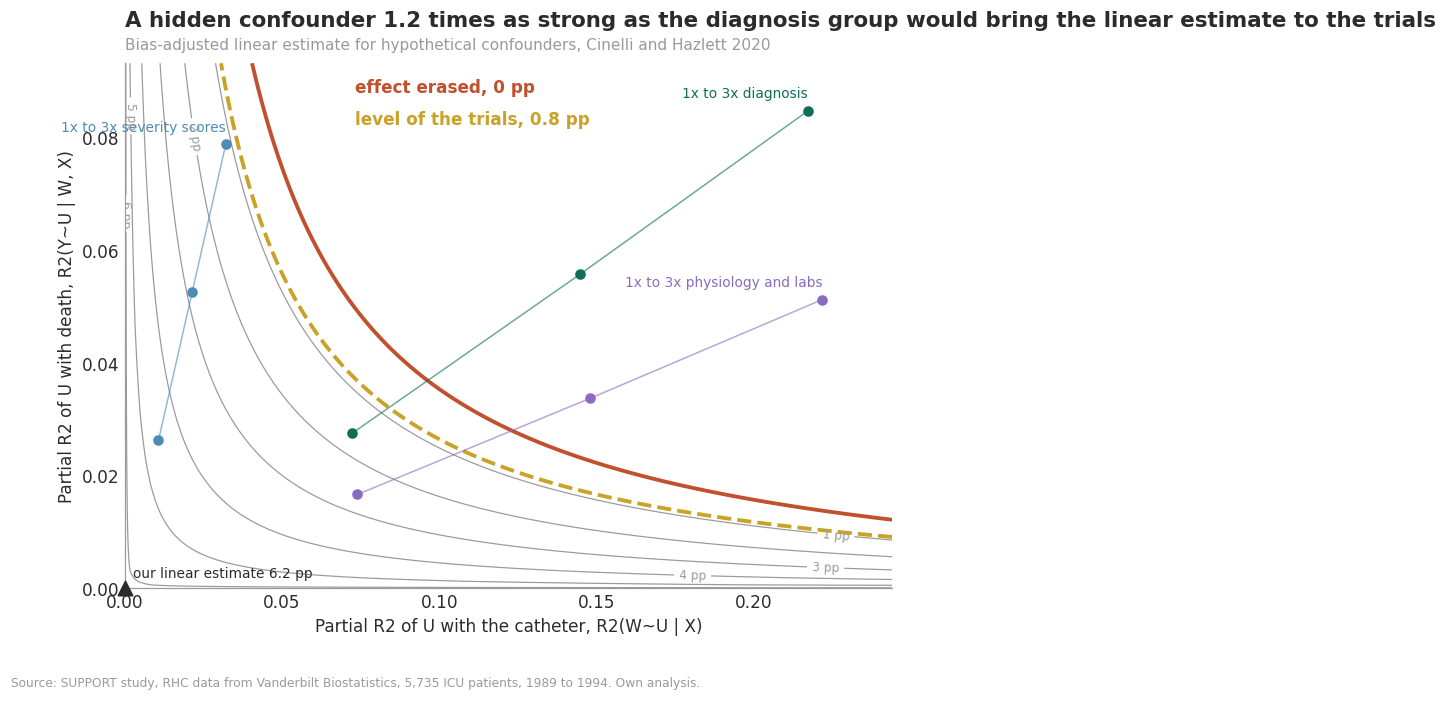

In [73]:
# Contour plot: every point is a hypothetical U, the lines show what our linear estimate would become.
# The axes reach just beyond the strongest benchmark, so every point stays visible
x_max = 1.1 * max(sens["R2(W~U|X)"].max(), rv)
y_max = 1.1 * max(sens["R2(Y~U|W,X)"].max(), rv)
RW, RY = np.meshgrid(np.linspace(0, x_max, 151), np.linspace(0, y_max, 151))
ADJ = (est - se_lin * np.sqrt(dof) * np.sqrt(RY * RW / (1 - RW))) * 100

fig, ax = plt.subplots(figsize=(9, 6.2))
cs = ax.contour(RW, RY, ADJ, levels=np.arange(1, est * 100, 1), colors=GREY, linewidths=0.8)
ax.clabel(cs, fmt="%.0f pp", fontsize=8)
ax.contour(RW, RY, ADJ, levels=[rd_rct * 100], colors=GOLD, linewidths=2.5, linestyles="--")
ax.contour(RW, RY, ADJ, levels=[0], colors=ACCENT_2, linewidths=2.5)
ax.text(0.30, 0.97, "effect erased, 0 pp", color=ACCENT_2, ha="left", va="top", fontweight="bold", transform=ax.transAxes)
ax.text(0.30, 0.91, f"level of the trials, {rd_rct * 100:.1f} pp", color=GOLD, ha="left", va="top",
        fontweight="bold", transform=ax.transAxes)
ax.scatter([0], [0], marker="^", s=90, color=DARK, zorder=3, clip_on=False)
# The labels sit in a legend next to the plot, so no text lies on the contour lines
legend_items = [Line2D([0], [0], marker="^", color="none", markerfacecolor=DARK, markeredgecolor=DARK,
                       markersize=9, label=f"our linear estimate, {est * 100:.1f} pp")]
for label, col in zip(BENCHMARKS, [ACCENT, "#4C8CB5", "#8A6BBE"]):
    pts = sens[sens.index.str.endswith(label)]
    ax.plot(pts["R2(W~U|X)"], pts["R2(Y~U|W,X)"], color=col, lw=1, alpha=0.6)
    ax.scatter(pts["R2(W~U|X)"], pts["R2(Y~U|W,X)"], color=col, s=35, zorder=3)
    legend_items.append(Line2D([0], [0], marker="o", color=col, lw=1, alpha=0.8, markersize=6,
                               label=f"1x to 3x {label}"))
ax.legend(handles=legend_items, loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False, fontsize=9)
ax.set_xlim(0, x_max); ax.set_ylim(0, y_max)
ax.set_xlabel("Partial R2 of U with the catheter, R2(W~U | X)")
ax.set_ylabel("Partial R2 of U with death, R2(Y~U | W, X)")
k_best = min(k_rct, key=lambda k_: k_rct[k_] if np.isfinite(k_rct[k_]) else np.inf)   # benchmark with the smallest k
k_txt = f"{k_rct[k_best]:.1f} times" if np.isfinite(k_rct[k_best]) else "more than 100 times"
titles(ax, f"A hidden confounder {k_txt} as strong as the {k_best} group would bring the linear estimate to the trials",
       "Bias-adjusted linear estimate for hypothetical confounders, Cinelli and Hazlett 2020")
save(fig, "fig07c_sensitivity_contour")

The linear estimate is 6.2 pp, 95% CI 3.6 to 8.8. A hidden confounder that explains 6.1% of the remaining variance of both the catheter decision and death would erase it, 5.3% would move it to the level of the trials. For the smaller causal forest estimate, about 3.5% would be enough to erase it.

Measured against what we have, such a confounder would need 1.2 times the strength of all twelve diagnosis variables together, or 1.5 times that of all physiology and lab values. That is a strong confounder, but not an absurd one. The severity physicians saw at the bedside, how the patient looked and how fast things got worse, plausibly drives both the decision and survival, and the recorded values capture it only in part. The gap to the trials therefore does not prove that the catheter caused harm, and a confounder of this strength cannot be ruled out.

### 7.5 Specification

In [74]:
# [CONCEPT] Two choices that could drive the result: the patients at the edge and the nuisance models
# [WHY]     Trimming drops every patient with a propensity outside 0.1 to 0.9 from Step 4 and averages the
#           doubly robust scores of the rest. The nuisance check compares the two AIPW estimates from 5.4.
#           Both pass if the estimate moves by less than one standard error
keep = (e_lr >= PS_LOW) & (e_lr <= PS_HIGH)
ate_trim, se_trim = Gamma[keep].mean(), Gamma[keep].std(ddof=1) / np.sqrt(keep.sum())
ate_logit = ladder.loc["AIPW: logistic regression", "estimate"]
TRIM_OK = abs(ate_trim - ate_cf) < se_cf
NUIS_OK = abs(ate_logit - ate_cf) < se_cf
print(f"Trimmed to {PS_LOW} to {PS_HIGH}, {keep.sum():,} patients: "
      f"{fmt_ci(ate_trim * 100, (ate_trim - Z_CRIT * se_trim) * 100, (ate_trim + Z_CRIT * se_trim) * 100)}")
print(f"All patients:                          {fmt_ci(ate_cf * 100, *(RESULTS['cf_ate_ci'][i] * 100 for i in (0, 1)))}")
print(f"AIPW with logistic nuisance models:    {ate_logit * 100:.1f} pp, difference {abs(ate_logit - ate_cf) * 100:.1f} pp, "
      f"one standard error = {se_cf * 100:.1f} pp")
RESULTS.update({"ate_trimmed": ate_trim, "ate_trimmed_se": se_trim, "n_trimmed_kept": int(keep.sum())})

Trimmed to 0.1 to 0.9, 4,721 patients: 3.7 pp, 95% CI 0.9 to 6.5
All patients:                          3.5 pp, 95% CI 1.0 to 6.1
AIPW with logistic nuisance models:    6.8 pp, difference 3.2 pp, one standard error = 1.3 pp


Dropping the 1,014 patients outside 0.1 to 0.9 hardly changes anything, 3.7 against 3.5 pp. The choice of nuisance models does: logistic regression gives 6.8 pp, 3.2 pp more and well over one standard error. This was already visible in 5.4 and stays the largest uncertainty about the size of the effect.

### 7.6 Robustness scorecard

                        check                                                   result  passed
        7.1 Placebo treatment             placebo mean -0.15 pp, real effect p = 0.048    True
      7.2 Random common cause                                    largest shift 0.30 pp    True
7.3 Semi-synthetic, no effect                             bias +0.91 pp, naive +4.2 pp   False
   7.4 Unmeasured confounding RV = 6%, trials reached by U of 1.2x the diagnosis group   False
   7.5 Trimming to 0.1 to 0.9                                        3.7 pp vs. 3.5 pp    True
          7.5 Nuisance models                        6.8 pp logistic vs. 3.5 pp forest   False


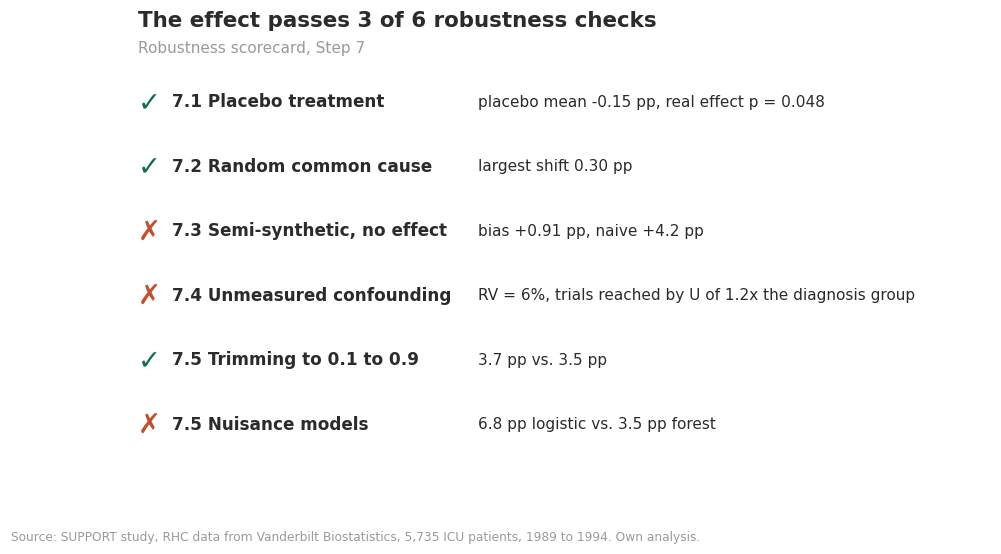

In [75]:
# [CONCEPT] One table with every check from Step 7, so nothing gets lost in the scrolling
k_best_txt = f"{k_rct[k_best]:.1f}x the {k_best} group"
scorecard = pd.DataFrame([
    ["7.1 Placebo treatment", f"placebo mean {placebo_ates.mean() * 100:+.2f} pp, real effect p = {p_placebo:.3f}", PLACEBO_OK],
    ["7.2 Random common cause", f"largest shift {rcc_shift * 100:.2f} pp", RCC_OK],
    ["7.3 Semi-synthetic, no effect", f"bias {semi_summary.loc['no effect', 'bias'] * 100:+.2f} pp, "
                                      f"naive {semi_summary.loc['no effect', 'naive'] * 100:+.1f} pp", SEMI_OK],
    ["7.4 Unmeasured confounding", f"RV = {rv:.0%}, trials reached by U of {k_best_txt}", SENS_OK],
    ["7.5 Trimming to 0.1 to 0.9", f"{ate_trim * 100:.1f} pp vs. {ate_cf * 100:.1f} pp", TRIM_OK],
    ["7.5 Nuisance models", f"{ate_logit * 100:.1f} pp logistic vs. {ate_cf * 100:.1f} pp forest", NUIS_OK],
], columns=["check", "result", "passed"])
n_pass = int(scorecard["passed"].sum())
RESULTS["robustness_passed"] = f"{n_pass}/{len(scorecard)}"
print(scorecard.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 0.62 * len(scorecard) + 1.0))
ax.axis("off")
ax.set_xlim(0, 1); ax.set_ylim(-0.6, len(scorecard) - 0.4)
for i, row in enumerate(scorecard.itertuples()):
    yv = len(scorecard) - 1 - i
    mark, col = ("✓", ACCENT) if row.passed else ("✗", ACCENT_2)
    ax.text(0.0, yv, mark, color=col, fontsize=18, fontweight="bold", va="center")
    ax.text(0.04, yv, row.check, fontsize=11, fontweight="bold", color=DARK, va="center")
    ax.text(0.40, yv, row.result, fontsize=10, color=DARK, va="center")
titles(ax, f"The effect passes {n_pass} of {len(scorecard)} robustness checks", "Robustness scorecard, Step 7")
save(fig, "fig07d_robustness_scorecard")

Three of the checks have a known right answer. A random treatment must show no effect, a noise column must change nothing, and a simulated outcome must return the built-in effect. Two of them pass. On simulated outcomes the pipeline removes most of the built-in confounding, but a positive bias of up to 0.9 pp remains. The other three checks have no known answer and show how far the real estimate moves when the analysis changes. Trimming barely moves it, swapping the nuisance models moves it a lot, and the sensitivity analysis shows how strong hidden confounding would have to be. None of the checks with a known answer can detect unmeasured confounding. The three failed checks are not bugs to fix but limits to report. A small bias from measured confounding remains, the size of the effect depends on the nuisance models, and in the linear model, a hidden confounder somewhat stronger than all recorded diagnosis variables could close the gap to the trials.

---
## Step 8. Interpretation

The best linear projection shows trends, partial dependence shows shape, the profiles make it concrete. Step 6 found no reliable differences between patients, so everything in this step is exploratory.

### 8.1 Best linear projection

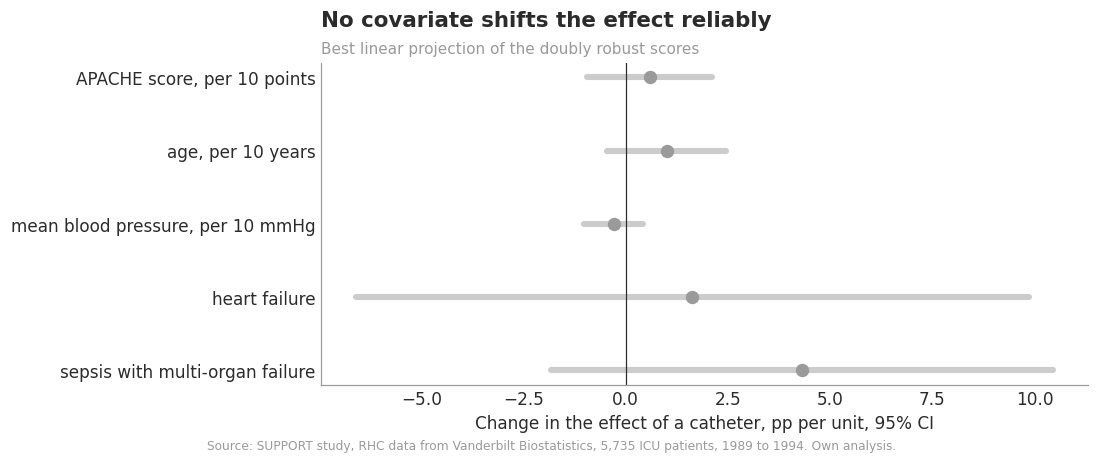

,"coef, pp","se, pp",p,"ci_low, pp","ci_high, pp"
const,3.540,1.306,0.007,0.980,6.099
"APACHE score, per 10 points",0.588,0.780,0.451,-0.940,2.117
"age, per 10 years",0.998,0.746,0.181,-0.463,2.460
"mean blood pressure, per 10 mmHg",-0.295,0.369,0.424,-1.018,0.428
heart failure,1.630,4.200,0.698,-6.601,9.862
sepsis with multi-organ failure,4.314,3.133,0.168,-1.826,10.455


In [76]:
# [CONCEPT] Best linear projection: OLS of the doubly robust scores on a few chosen covariates A
#           Gamma_i = beta_0 + A_i' beta + error, with HC3 standard errors
# [WHY]     A transparent summary of the black box: how does the effect change along A?
#           The slopes are trends, not causal effects of A, because A itself was not randomized.
#           Centring A makes the intercept the ATE for an average patient
A = pd.DataFrame({
    "APACHE score, per 10 points": (df["aps1"] - df["aps1"].mean()) / 10,
    "age, per 10 years": (df["age"] - df["age"].mean()) / 10,
    "mean blood pressure, per 10 mmHg": (df["meanbp1"] - df["meanbp1"].mean()) / 10,
    "heart failure": (df["cat1"] == "CHF") - (df["cat1"] == "CHF").mean(),
    "sepsis with multi-organ failure": (df["cat1"] == "MOSF w/Sepsis") - (df["cat1"] == "MOSF w/Sepsis").mean(),
})
blp = sm.OLS(Gamma, sm.add_constant(A)).fit(cov_type="HC3")
blp_tab = pd.DataFrame({"coef, pp": blp.params * 100, "se, pp": blp.bse * 100, "p": blp.pvalues})
blp_tab["ci_low, pp"] = blp_tab["coef, pp"] - Z_CRIT * blp_tab["se, pp"]
blp_tab["ci_high, pp"] = blp_tab["coef, pp"] + Z_CRIT * blp_tab["se, pp"]
RESULTS.update({f"blp_{k}": v / 100 for k, v in blp_tab["coef, pp"].items()})
RESULTS.update({f"blp_p_{k}": v for k, v in blp_tab["p"].items()})

slopes = blp_tab.drop(index="const")
fig, ax = plt.subplots(figsize=(9, 3.8))
yy = np.arange(len(slopes))[::-1]
for yi, (name, row) in zip(yy, slopes.iterrows()):
    col = ACCENT if row["p"] < ALPHA else GREY
    ax.plot([row["ci_low, pp"], row["ci_high, pp"]], [yi, yi], color=col, lw=4, alpha=0.5, solid_capstyle="round")
    ax.scatter(row["coef, pp"], yi, color=col, s=60, zorder=3)
ax.axvline(0, color=DARK, lw=0.8)
ax.set_yticks(yy, labels=slopes.index)
ax.set_xlabel("Change in the effect of a catheter, pp per unit, 95% CI")
titles(ax, "No covariate shifts the effect reliably" if (slopes["p"] >= ALPHA).all()
       else "Some covariates shift the effect",
       "Best linear projection of the doubly robust scores")
save(fig, "fig08a_blp")
blp_tab.round(3)

All slopes point in a plausible direction, but none is significant. The effect grows by 0.6 pp per 10 APACHE points and by 1.0 pp per 10 years of age, and it is 4.3 pp larger in sepsis with multi-organ failure, p = 0.17. Step 7.3 showed that a slope of 2 pp per 10 APACHE points is found significant in only 8 of 20 replicates, so a real trend of that size cannot be ruled out: the interval for APACHE reaches up to 2.1 pp.

### 8.2 Partial dependence

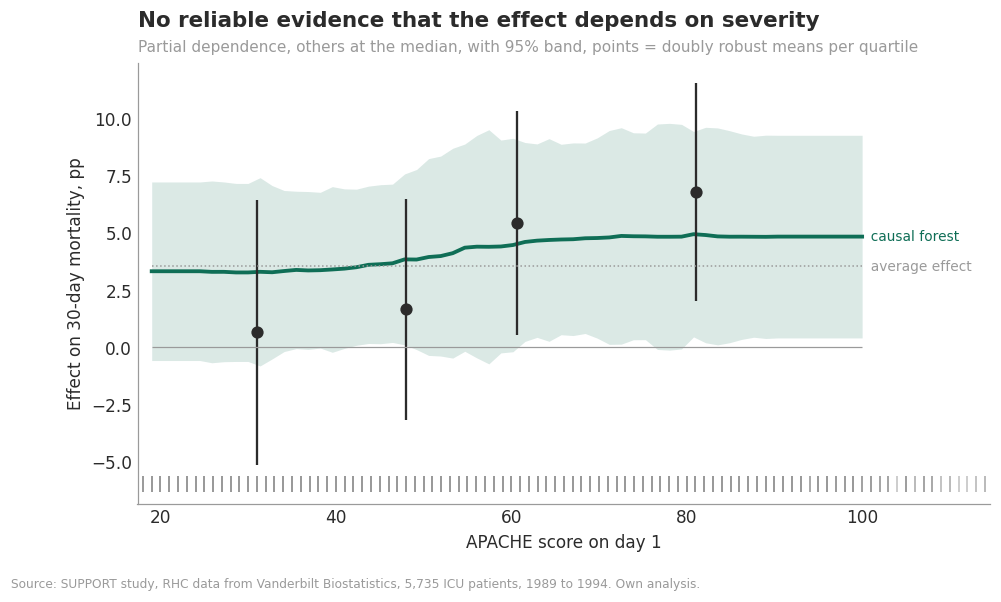

                  x  est   se     n
bin                                
(2.999, 41.0]  31.0  0.6  2.9  1512
(41.0, 54.0]   48.0  1.7  2.5  1471
(54.0, 67.0]   60.6  5.4  2.5  1321
(67.0, 147.0]  81.0  6.8  2.4  1431 



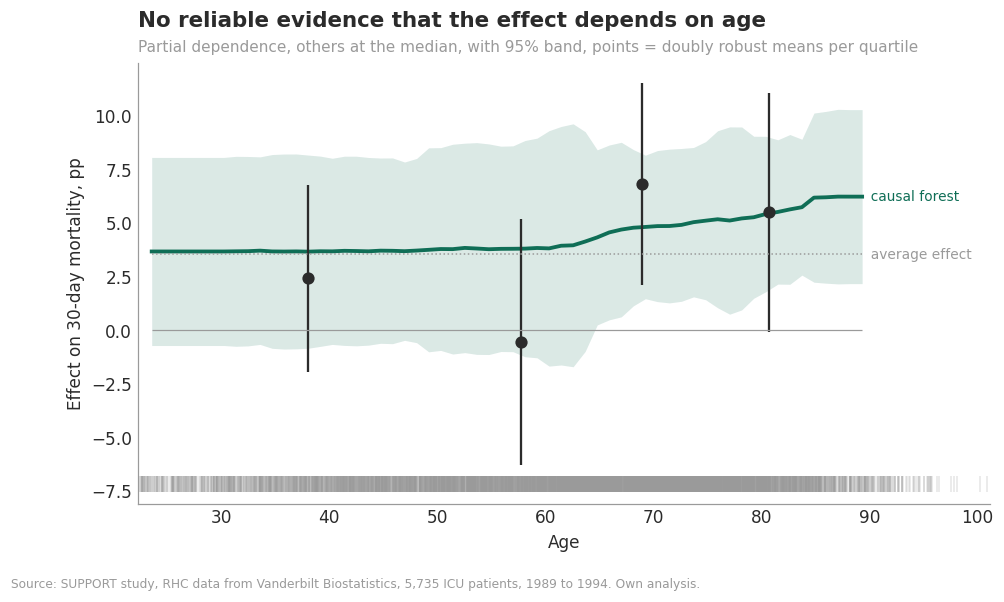

                      x  est   se     n
bin                                    
(18.041, 50.149]   38.1  2.4  2.2  1434
(50.149, 64.047]   57.7 -0.6  2.9  1434
(64.047, 73.932]   69.0  6.8  2.4  1433
(73.932, 101.848]  80.7  5.5  2.8  1434


In [77]:
# [CONCEPT] Partial dependence: vary one covariate over a grid, hold all others at their median,
#           predict tau(x) with a 95% band from the forest's variance estimate
# [WHY]     Shows the shape the forest has learned. The dark points are a check with the doubly robust scores:
#           the mean of the doubly robust scores within quartiles of the real data.
#           Two caveats: the median patient may sit where data are sparse, and varying one covariate
#           with everything else frozen need not describe any real group of patients
X_median = np.median(X, axis=0)


def partial_dependence(col, grid):
    X_grid = np.tile(X_median, (len(grid), 1))
    X_grid[:, X_df.columns.get_loc(col)] = grid
    pred, var = cf.predict_and_var(X_grid)
    return pred.ravel(), np.sqrt(var.ravel())


def binned_scores(col):
    tab = pd.DataFrame({"bin": pd.qcut(df[col], 4), "G": Gamma, "x": df[col]})
    return tab.groupby("bin", observed=True).agg(
        x=("x", "mean"), est=("G", "mean"), se=("G", lambda s: s.std(ddof=1) / np.sqrt(len(s))), n=("G", "size"))


def plot_pd(col, xlabel, blp_row, fname, words):
    grid = np.linspace(*np.percentile(df[col], [2, 98]), 60)
    pd_est, pd_se = partial_dependence(col, grid)
    bins_ = binned_scores(col)
    fig, ax = plt.subplots(figsize=(10, 5.9))   # taller than before, so the strip does not squeeze the plot
    ax.fill_between(grid, (pd_est - Z_CRIT * pd_se) * 100, (pd_est + Z_CRIT * pd_se) * 100, color=ACCENT, alpha=0.15, lw=0)
    ax.plot(grid, pd_est * 100, color=ACCENT, lw=2.5)
    ax.errorbar(bins_["x"], bins_["est"] * 100, yerr=Z_CRIT * bins_["se"] * 100, fmt="o", color=DARK, ms=7, lw=1.5, capsize=0)
    ax.hlines(ate_cf * 100, grid[0], grid[-1], color=GREY, ls=":", lw=1)
    ax.hlines(0, grid[0], grid[-1], color=GREY, lw=0.8)
    ax.text(grid[-1], pd_est[-1] * 100, "  causal forest", color=ACCENT, va="center", fontsize=9)
    ax.text(grid[-1], ate_cf * 100, "  average effect", color=GREY, va="center", fontsize=9)
    x_lo, x_hi = grid[0] - (grid[-1] - grid[0]) * 0.02, grid[-1] + (grid[-1] - grid[0]) * 0.18
    ax.set_xlim(x_lo, x_hi)
    # Strip of bars below the plot: how many patients lie in each bin. A rug of single ticks cannot show this,
    # because ticks with many patients on the same integer value all look equally dark
    y_lo, y_hi = ax.get_ylim()
    strip = 0.10 * (y_hi - y_lo)
    ax.set_ylim(y_lo - 1.4 * strip, y_hi)
    ax.set_yticks([t for t in ax.get_yticks() if y_lo <= t <= y_hi])
    counts, edges = np.histogram(df[col], bins=np.linspace(x_lo, x_hi, 31))
    ax.bar(edges[:-1], counts / counts.max() * strip, width=np.diff(edges), align="edge", bottom=y_lo - 1.4 * strip,
           color=GREY, alpha=0.5, lw=0)
    ax.text(x_hi, y_lo - 0.4 * strip, "patients per bin", color=GREY, fontsize=8, ha="right", va="bottom")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Effect on 30-day mortality, pp")
    sig = blp_tab.loc[blp_row, "p"] < ALPHA
    direction = "grows" if blp_tab.loc[blp_row, "coef, pp"] > 0 else "shrinks"
    titles(ax, f"The effect {direction} with {words}" if sig else f"No reliable evidence that the effect depends on {words}",
           "Partial dependence, others at the median, with 95% band, points = doubly robust means per quartile")
    save(fig, fname)
    return bins_


bins_aps = plot_pd("aps1", "APACHE score on day 1", "APACHE score, per 10 points", "fig08b_pd_apache", "severity")
print((bins_aps.assign(est=bins_aps["est"] * 100, se=bins_aps["se"] * 100)).round(1).to_string(), "\n")
bins_age = plot_pd("age", "Age", "age, per 10 years", "fig08c_pd_age", "age")
print((bins_age.assign(est=bins_age["est"] * 100, se=bins_age["se"] * 100)).round(1).to_string())

The forest's curve rises gently with severity, from about 3.3 pp at low APACHE scores to 4.9 pp at high ones. The doubly robust means per quartile rise more steeply, from 0.6 to 6.8 pp, but each has an interval of about ±5 pp. For age there is no clear pattern: 2.4, −0.6, 6.8 and 5.5 pp. If the estimated effect is larger in any group, sicker patients are the most likely candidates, but the data cannot confirm it. The bars below each plot show how many patients lie in each range, so the edges of the curve rest on fewer patients.

### 8.3 Illustrative profiles

                                                      tau, pp  ci_low, pp  ci_high, pp
Heart failure: 70 years, APACHE 40                        3.9         1.4          6.5
Typical patient: median on every column                   4.3        -0.3          8.9
Septic shock: 60 years, APACHE 80, blood pressure 50      5.7         1.3         10.1


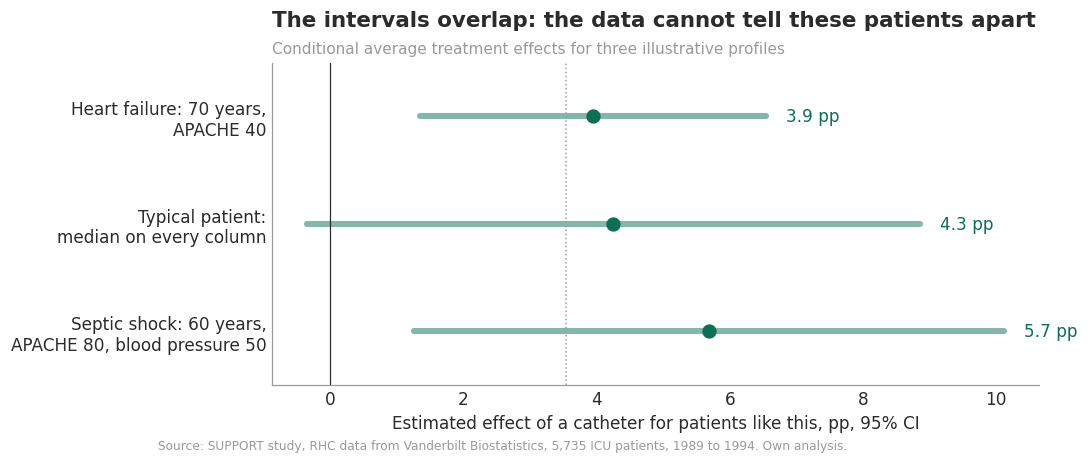

In [78]:
# [CONCEPT] Effects for three illustrative patients. Columns not named stay at the median of all patients
# [WHY]     Useful for telling the story, but tau(x) is the average effect for patients LIKE this profile,
#           not what would happen to one particular person.
#           A disease category is set through its one-hot column, e.g. "cat1_CHF" = 1, the reference is ARF
profiles = {
    "Heart failure: 70 years,\nAPACHE 40": {"cat1_CHF": 1, "card": 1, "age": 70, "aps1": 40},
    "Typical patient:\nmedian on every column": {},
    "Septic shock: 60 years,\nAPACHE 80, blood pressure 50": {"cat1_MOSF w/Sepsis": 1, "seps": 1, "age": 60,
                                                              "aps1": 80, "meanbp1": 50},
}
base_profile = dict(zip(X_df.columns, X_median))
X_prof = np.array([[{**base_profile, **p}[c] for c in X_df.columns] for p in profiles.values()], dtype=float)
tau_prof = cf.predict(X_prof).ravel()
lo_prof, hi_prof = (a.ravel() for a in cf.predict_interval(X_prof, alpha=ALPHA))
prof_tab = pd.DataFrame({"tau, pp": tau_prof * 100, "ci_low, pp": lo_prof * 100, "ci_high, pp": hi_prof * 100},
                        index=[k.replace("\n", " ") for k in profiles])
print(prof_tab.round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 3.8))
yy = np.arange(len(profiles))[::-1]
for yi, t_, l_, h_ in zip(yy, tau_prof * 100, lo_prof * 100, hi_prof * 100):
    ax.plot([l_, h_], [yi, yi], color=ACCENT, lw=4, alpha=0.5, solid_capstyle="round")
    ax.scatter(t_, yi, color=ACCENT, s=70, zorder=3)
    ax.text(h_ + 0.3, yi, f"{t_:.1f} pp", va="center", color=ACCENT)
ax.axvline(ate_cf * 100, color=GREY, ls=":", lw=1)
ax.axvline(0, color=DARK, lw=0.8)
ax.set_yticks(yy, labels=list(profiles))
ax.set_ylim(-0.5, len(profiles) - 0.5)
ax.set_xlabel("Estimated effect of a catheter for patients like this, pp, 95% CI")
overlap = lo_prof.max() < hi_prof.min()
titles(ax, "The intervals overlap: the data cannot tell these patients apart" if overlap
       else "The profiles differ in their expected effect",
       "Conditional average treatment effects for three illustrative profiles")
save(fig, "fig08d_profiles")

For a 70-year-old with heart failure and a moderate APACHE score the forest estimates 3.9 pp, for a typical patient 4.3 pp, for a 60-year-old in septic shock 5.7 pp. The intervals overlap widely. The order fits the trend from 8.1, but the profiles cannot be told apart.

### 8.4 Summary and export

In [79]:
# [CONCEPT] Executive summary in the Minto structure: main idea first, then three key lines.
#           Every number comes from RESULTS or the tables above, so the text updates with the analysis
lo_cf, hi_cf = RESULTS["cf_ate_ci"]
adjusted = ladder["estimate"].iloc[1:]
rate_sig = any(rr["autoc"] - Z_CRIT * rr["se"] > 0 for rr in rate_res.values())
blp_sig = bool((slopes["p"] < ALPHA).any())
evidence = (f"calibration beta = {calib['beta']:.2f}, one-sided p = {calib['p_beta_gt_0']:.2f}; "
            f"RATE {'significant' if rate_sig else 'not significant'}; "
            f"best linear projection {'with significant slopes' if blp_sig else 'without significant slopes'}")
het_line = (f"The effect differs between patients: {evidence}." if HETEROGENEITY_DETECTED else
            f"There is no reliable evidence that it differs between patients: {evidence}.")
sign_line = ("all point estimates above zero" if (adjusted > 0).all() else "not all of them above zero")
summary = f"""
MAIN IDEA
  After adjusting for 50 covariates from day 1, a right heart catheter goes with {ate_cf * 100:.1f} percentage points
  higher 30-day mortality, 95% CI {lo_cf * 100:.1f} to {hi_cf * 100:.1f}.
  {het_line}

KEY LINE 1: the raw comparison overstates the harm
  Raw difference {naive * 100:.1f} pp. Catheter patients were sicker, the largest ASMD before weighting is
  {RESULTS['asmd_max_unadjusted']:.2f}, after overlap weighting every ASMD is below {RESULTS['asmd_max_overlap']:.3f}.

KEY LINE 2: the size depends on the model
  {len(adjusted)} adjusted estimators between {adjusted.min() * 100:.1f} and {adjusted.max() * 100:.1f} pp, {sign_line}.
  {n_pass} of {len(scorecard)} robustness checks passed.

KEY LINE 3: a hidden confounder could explain the gap to the trials
  The trials point to about {rd_rct * 100:.1f} pp. In the linear model, {RESULTS['sens_estimate_linear'] * 100:.1f} pp,
  a hidden confounder {k_rct[k_best]:.1f} times as strong as the {k_best} group would close the gap,
  robustness value {RESULTS['sens_rv_rct']:.0%}. Severity seen at the bedside is a plausible candidate.
  The exclusion of patients who died or left the hospital within 48 hours may bias the estimate either way.
"""
print(summary)


def to_builtin(v):
    # json cannot store numpy types, so convert them to plain Python numbers, bools and lists
    if isinstance(v, (np.floating, np.integer)):
        return v.item()
    if isinstance(v, np.bool_):
        return bool(v)
    if isinstance(v, (tuple, list)):
        return [to_builtin(x) for x in v]
    return v


RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)
with open(RESULTS_DIR / "results_summary.json", "w") as fh:
    json.dump({k: to_builtin(v) for k, v in RESULTS.items()}, fh, indent=2)
ladder.round(4).to_csv(RESULTS_DIR / "ate_ladder.csv")
cf_effects.round(4).to_csv(RESULTS_DIR / "estimands.csv")
sens.round(4).to_csv(RESULTS_DIR / "sensitivity.csv")
scorecard.to_csv(RESULTS_DIR / "robustness_scorecard.csv", index=False)
blp_tab.round(4).to_csv(RESULTS_DIR / "best_linear_projection.csv")
(RESULTS_DIR / "executive_summary.txt").write_text(summary, encoding="utf-8")
print("Exported to", RESULTS_DIR.resolve(), "and figures to", FIG_DIR.resolve())


MAIN IDEA
  After adjusting for 50 covariates from day 1, a right heart catheter goes with 3.5 percentage points
  higher 30-day mortality, 95% CI 1.0 to 6.1.
  There is no reliable evidence that it differs between patients: calibration beta = 0.24, one-sided p = 0.39; RATE not significant; best linear projection without significant slopes.

KEY LINE 1: the raw comparison overstates the harm
  Raw difference 7.4 pp. Catheter patients were sicker, the largest ASMD before weighting is
  0.35, after overlap weighting every ASMD is below 0.013.

KEY LINE 2: the size depends on the model
  4 adjusted estimators between 3.5 and 6.8 pp, all point estimates above zero.
  3 of 6 robustness checks passed.

KEY LINE 3: a hidden confounder could explain the gap to the trials
  The trials point to about 0.8 pp. In the linear model, 6.2 pp,
  a hidden confounder 1.2 times as strong as the diagnosis group would close the gap,
  robustness value 5%. Severity seen at the bedside is a plausible candida

### 8.5 Limitations and conclusion

- **Unmeasured severity.** The main threat. In the linear model of Step 7.4, a hidden confounder 1.2 times as strong as all recorded diagnosis variables could explain the whole gap to the trials.
- **Selection in the first 48 hours.** Patients who died or left within two days are not in the data, Step 3.1. The direction of the resulting bias is unknown.
- **Model dependence.** Forest nuisance models give 3.5 pp, logistic ones 6.8 pp. Both fit about equally well, so the size of the effect is uncertain by about 3 pp beyond the confidence interval.
- **Time and place.** The data describe catheter use in five US teaching hospitals between 1989 and 1994. The trials enrolled other patients, and practice has changed since.
- **Conversion.** The odds ratios of Connors et al. and the trials were converted at our baseline risk of 30.6%, which makes the comparison approximate.

After adjustment, the catheter still goes with higher mortality, but by about half of the raw difference and with an estimate that depends on the model. Our analysis cannot tell whether this remainder is real harm or the severity physicians saw at the bedside. The randomized trials, which do not have this problem, found no clear effect. The honest reading is that observational data like these could not have settled the question in 1996, and the call for a moratorium rested on an estimate that was more fragile than it looked.